# MAI391 — Computer Project: Gradient Descent (Câu 1–10)

Notebook này chứa trực tiếp mã triển khai và kiểm chứng cho từng câu trong các ô code bên dưới. Không cần gọi `run_question()` hay chạy script bên ngoài; các file mã nguồn kèm theo chỉ là bản tham khảo. Chạy **Run All** từ đầu đến cuối để tái tạo dữ liệu, kết quả và hình.

**Dữ liệu:** Combined Cycle Power Plant (9.568 quan sát; UCI Machine Learning Repository, DOI [10.24432/C5002N](https://doi.org/10.24432/C5002N)). Mô hình hồi quy đơn dùng nhiệt độ môi trường `AT` (°C) để dự đoán công suất điện `PE` (MW). Câu 1–8 là phần bắt buộc; câu 9–10 là phần cộng điểm.

## Chuẩn bị môi trường

Chọn kernel Python có các thư viện trong `requirements.txt`. Nếu cần cài đặt, mở terminal tại thư mục `MAI391_Code` và chạy `python -m pip install -r requirements.txt`. Workbook gốc đã được kèm trong `data/raw/`; nếu kernel không thấy file này, ô khởi tạo sẽ thử tải từ UCI (cần Internet).

In [35]:
from pathlib import Path
import os
import sys
from io import BytesIO
from urllib.request import urlopen
from zipfile import BadZipFile, ZipFile
from urllib.error import URLError
from IPython.display import display, Image, Markdown

# Locate the project folder; all task implementations are embedded in this notebook.
_candidates = [Path.cwd(), Path.cwd() / "MAI391_Code", *Path.cwd().parents]
ROOT = next((p.resolve() for p in _candidates if (p / "data/raw/Folds5x2_pp.xlsx").is_file()), None)
if ROOT is None:
    # Cloud notebook kernels may not have the adjacent data folder; retrieve the cited public UCI workbook.
    ROOT = Path.cwd().resolve()
    _raw_dir = ROOT / "data" / "raw"
    _raw_dir.mkdir(parents=True, exist_ok=True)
    _dataset_url = "https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip"
    try:
        with urlopen(_dataset_url, timeout=60) as _response:
            _archive = ZipFile(BytesIO(_response.read()))
        _workbook_members = [name for name in _archive.namelist() if name.lower().endswith("/folds5x2_pp.xlsx")]
        if len(_workbook_members) != 1:
            raise FileNotFoundError("The UCI archive did not contain exactly one Folds5x2_pp.xlsx workbook.")
        (_raw_dir / "Folds5x2_pp.xlsx").write_bytes(_archive.read(_workbook_members[0]))
    except (OSError, URLError, BadZipFile) as _error:
        raise RuntimeError(
            "Could not find or download the dataset. Upload the UCI Folds5x2_pp.xlsx workbook to "
            "data/raw/ and rerun this cell."
        ) from _error
    print("Downloaded the Combined Cycle Power Plant workbook from UCI.")
os.chdir(ROOT)
os.environ["MPLBACKEND"] = "Agg"
print(f"Project folder: {ROOT}")
print(f"Python: {sys.executable}")


Project folder: /content
Python: /usr/bin/python3


## Câu 1 — Thu thập và chuẩn bị dữ liệu

Đọc `Sheet1` từ workbook gốc, kiểm tra dữ liệu, loại bản sao trùng hoàn toàn, giữ mã dòng Excel để truy vết, chia train/test theo seed 42 (80/20) và chuẩn hóa `AT` bằng thống kê của train. Các bước kiểm chứng ghi lại quy mô dữ liệu và tạo hợp đồng dữ liệu có SHA-256.

In [36]:
"""Câu 1 - Chuẩn bị dữ liệu (TV2)."""
from pathlib import Path
import json
import numpy as np
import pandas as pd

_notebook_root_candidates = [Path.cwd(), Path.cwd() / "MAI391_Code", *Path.cwd().parents]
ROOT = next((p.resolve() for p in _notebook_root_candidates if (p / "data/raw/Folds5x2_pp.xlsx").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy data/raw/Folds5x2_pp.xlsx. Hãy mở notebook từ thư mục MAI391_Code.")
_nb_data_prep_RAW = ROOT / "data/raw/Folds5x2_pp.xlsx"
_nb_data_prep_PROC = ROOT / "data/processed"
_nb_data_prep_RES = ROOT / "results"
SEED, TEST_FRAC, DDOF = 42, 0.20, 0
_nb_data_prep_COLS = ["AT", "V", "AP", "RH", "PE"]


def _nb_data_prep_main():
    _nb_data_prep_PROC.mkdir(parents=True, exist_ok=True); _nb_data_prep_RES.mkdir(parents=True, exist_ok=True)
    df = pd.read_excel(_nb_data_prep_RAW, sheet_name="Sheet1")           # chỉ đọc Sheet1
    df.insert(0, "source_row", np.arange(2, len(df) + 2))   # số dòng Excel (header = dòng 1)
    audit = []
    def log(item, value, note=""):
        audit.append({"item": item, "value": value, "note": note})

    log("rows_raw", len(df), "Sheet1 của Folds5x2_pp.xlsx")
    for c in _nb_data_prep_COLS:
        log(f"dtype_{c}", str(df[c].dtype))
        log(f"missing_{c}", int(df[c].isna().sum()))
        log(f"nonfinite_{c}", int((~np.isfinite(df[c])).sum()))
    log("invalid_AT_range", int(((df.AT < -50) | (df.AT > 60)).sum()), "AT ngoài [-50,60] °C")
    log("invalid_PE_nonpositive", int((df.PE <= 0).sum()), "PE <= 0 MW")
    log("invalid_RH_range", int(((df.RH < 0) | (df.RH > 100.5)).sum()), "RH ngoài [0,100.5] %")
    dup_mask = df.duplicated(subset=_nb_data_prep_COLS, keep="first")
    log("duplicate_rows_full5", int(dup_mask.sum()), "trùng hoàn toàn cả 5 cột (giữ bản đầu)")
    log("rows_with_repeated_AT", int(df.duplicated(subset=["AT"], keep=False).sum()), "AT lặp - KHÔNG loại")
    log("outliers_removed", 0, "Không bỏ điểm cực trị")

    clean = df.loc[~dup_mask].reset_index(drop=True)
    log("rows_removed", int(dup_mask.sum()), "source_row bị loại: " + ",".join(map(str, df.source_row[dup_mask])))
    log("rows_clean", len(clean))
    assert len(clean) >= 500

    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(clean))
    n_test = int(round(TEST_FRAC * len(clean)))
    test = clean.iloc[np.sort(perm[:n_test])].reset_index(drop=True)
    train = clean.iloc[np.sort(perm[n_test:])].reset_index(drop=True)
    assert set(train.source_row).isdisjoint(test.source_row)
    log("rows_train", len(train)); log("rows_test", len(test))
        # Tính trung bình AT trên tập train
    n_train = len(train)
    total_at = 0.0
    for at in train["AT"]:
        total_at += at
    mean_at = total_at / n_train

    # Tính độ lệch chuẩn AT trên tập train
    squared_diff_sum = 0.0
    for at in train["AT"]:
        diff = at - mean_at
        squared_diff_sum += diff ** 2

    variance_at = squared_diff_sum / (n_train - DDOF)
    std_at = variance_at ** 0.5

    # Dùng cùng trung bình và độ lệch chuẩn để chuẩn hóa train và test
    for d in (train, test):
        d["AT_scaled"] = (d.AT - mean_at) / std_at

    mean_at = float(train.AT.mean()); std_at = float(train.AT.std(ddof=DDOF))
    for d in (train, test):
        d["AT_scaled"] = (d.AT - mean_at) / std_at
    clean.to_csv(_nb_data_prep_PROC / "clean.csv", index=False)
    train.to_csv(_nb_data_prep_PROC / "train.csv", index=False)
    test.to_csv(_nb_data_prep_PROC / "test.csv", index=False)
    scaling = {"variable": "AT", "target": "PE", "mean_AT": mean_at, "std_AT": std_at,
               "ddof": DDOF, "seed": SEED, "test_fraction": TEST_FRAC,
               "split_method": "numpy default_rng(seed).permutation trên clean.csv; giữ thứ tự source_row trong mỗi tập",
               "n_clean": len(clean), "n_train": len(train), "n_test": len(test),
               "units": {"AT": "°C", "PE": "MW"}}
    (_nb_data_prep_RES / "scaling.json").write_text(json.dumps(scaling, indent=2, ensure_ascii=False), encoding="utf-8")
    pd.DataFrame(audit).to_csv(_nb_data_prep_RES / "data_audit.csv", index=False)
    pd.DataFrame({"variable": _nb_data_prep_COLS,
        "meaning": ["Nhiệt độ môi trường TB theo giờ", "Chân không xả (Exhaust Vacuum)",
                    "Áp suất môi trường", "Độ ẩm tương đối", "Công suất điện ròng theo giờ"],
        "unit": ["°C", "cm Hg", "mbar", "%", "MW"]}).to_csv(_nb_data_prep_RES / "q1_variables.csv", index=False)
    print(pd.DataFrame(audit).to_string(index=False)); print(scaling)

"""Independent checks and fingerprints for the group's shared data handoff."""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

ROOT = ROOT
_nb_verify_data_COLS = ['AT', 'V', 'AP', 'RH', 'PE']

def _nb_verify_data_main():
    raw_file = ROOT / 'data/raw/Folds5x2_pp.xlsx'
    raw = pd.read_excel(raw_file, sheet_name='Sheet1')
    clean = pd.read_csv(ROOT / 'data/processed/clean.csv')
    train = pd.read_csv(ROOT / 'data/processed/train.csv')
    test = pd.read_csv(ROOT / 'data/processed/test.csv')
    sc = json.loads((ROOT / 'results/scaling.json').read_text(encoding='utf-8'))
    checks = []

    def check(name, condition):
        checks.append({'check': name, 'passed': bool(condition)})
        if not condition:
            raise ValueError('Data verification failed: ' + name)

    check('raw_columns_match', list(raw.columns) == _nb_verify_data_COLS)
    check('raw_is_finite', np.isfinite(raw[_nb_verify_data_COLS].to_numpy()).all())
    check('raw_row_count_9568', len(raw) == 9568)
    check('full_row_duplicates_41', int(raw.duplicated(_nb_verify_data_COLS).sum()) == 41)
    check('clean_row_count_9527', len(clean) == 9527)
    check('train_row_count_7622', len(train) == 7622)
    check('test_row_count_1905', len(test) == 1905)
    check('minimum_500_clean', len(clean) >= 500)
    check('no_remaining_full_row_duplicates', not clean.duplicated(_nb_verify_data_COLS).any())
    check('source_rows_are_unique', all(d.source_row.is_unique for d in (clean, train, test)))
    check('train_test_disjoint', set(train.source_row).isdisjoint(test.source_row))
    check('train_test_cover_clean', set(train.source_row) | set(test.source_row) == set(clean.source_row))

    expected = raw.copy()
    expected.insert(0, 'source_row', np.arange(2, len(raw) + 2))
    expected = expected.drop_duplicates(_nb_verify_data_COLS, keep='first').reset_index(drop=True)
    pd.testing.assert_frame_equal(clean, expected, check_exact=False, atol=1e-12, rtol=0)
    checks.append({'check': 'clean_matches_original_except_declared_dedup', 'passed': True})

    # Reconstruct the exact TV2 split, including row order.
    perm = np.random.default_rng(42).permutation(len(clean))
    n_test = int(round(.2 * len(clean)))
    expected_test_rows = clean.iloc[np.sort(perm[:n_test])].source_row.tolist()
    expected_train_rows = clean.iloc[np.sort(perm[n_test:])].source_row.tolist()
    check('exact_TV2_split_and_order', train.source_row.tolist() == expected_train_rows and test.source_row.tolist() == expected_test_rows)
    mu, sd = float(train.AT.mean()), float(train.AT.std(ddof=0))
    check('train_standard_deviation_positive', np.isfinite(sd) and sd > 0)
    check('saved_train_scaling', abs(sc['mean_AT'] - mu) < 1e-12 and abs(sc['std_AT'] - sd) < 1e-12)
    check('saved_counts_match', sc['n_clean'] == len(clean) and sc['n_train'] == len(train) and sc['n_test'] == len(test))
    for label, frame in [('train', train), ('test', test)]:
        check(label + '_is_finite', np.isfinite(frame[_nb_verify_data_COLS + ['AT_scaled']].to_numpy()).all())
        np.testing.assert_allclose(frame.AT_scaled, (frame.AT - mu) / sd, atol=1e-12, rtol=0)
        original_values = clean.set_index('source_row').loc[frame.source_row, _nb_verify_data_COLS].to_numpy()
        np.testing.assert_allclose(frame[_nb_verify_data_COLS].to_numpy(), original_values, atol=1e-12, rtol=0)
        checks.append({'check': label + '_values_and_scaling_match', 'passed': True})
    check('train_scaled_mean_zero', abs(float(train.AT_scaled.mean())) < 1e-12)
    check('train_scaled_std_one', abs(float(train.AT_scaled.std(ddof=0)) - 1) < 1e-12)

    paths = ['data/raw/Folds5x2_pp.xlsx', 'data/processed/clean.csv', 'data/processed/train.csv', 'data/processed/test.csv', 'results/scaling.json']
    contract = {
        'data_version': 'TV2_shared_v1',
        'source_dataset': 'Combined Cycle Power Plant',
        'source_url': 'https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant',
        'source_doi': '10.24432/C5002N',
        'sheet': 'Sheet1', 'feature': 'AT', 'target': 'PE',
        'n_raw': len(raw), 'n_clean': len(clean), 'n_train': len(train), 'n_test': len(test),
        'mean_AT': mu, 'std_AT': sd, 'ddof': 0, 'seed': 42,
        'split': 'default_rng(42); first round(0.2*n) permuted indices are test; source-row order preserved within each split',
        'deduplication': 'Keep first occurrence of identical five-column rows; retain other observations',
        'RH_above_100_raw': int((raw.RH > 100).sum()), 'RH_max_raw': float(raw.RH.max()),
        'sha256': {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in paths},
        'checks_passed': len(checks),
        'scope': 'Question 1 shared data only. No GD or model evaluation results included.'
    }
    (ROOT / 'results/data_contract.json').write_text(json.dumps(contract, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    pd.DataFrame(checks).to_csv(ROOT / 'results/q1_verification.csv', index=False, encoding='utf-8')
    print('\nQ1 DATA CHECK: PASS')
    print(f'raw={len(raw)}, clean={len(clean)}, train={len(train)}, test={len(test)}')
    print(f'mean_AT={mu:.12f}; std_AT={sd:.12f}; ddof=0')
    print(f'Checks passed: {len(checks)}')
    print('Shared data version: TV2_shared_v1')

_nb_data_prep_main()
_nb_verify_data_main()


                  item   value                                                                                                                                                                                                                             note
              rows_raw    9568                                                                                                                                                                                                      Sheet1 của Folds5x2_pp.xlsx
              dtype_AT float64                                                                                                                                                                                                                                 
            missing_AT       0                                                                                                                                                                                                          

## Câu 2 — Khám phá và trực quan hóa

Thống kê mô tả, tương quan Pearson, kiểm tra IQR và biểu đồ phân tán/phân phối/boxplot được tính trên tập train. Không huấn luyện mô hình và không loại thêm quan sát ở bước này.

In [37]:
"""Read the shared Q1 training data without re-splitting or changing scaling."""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

ROOT = ROOT

def _nb_data_io_verify_shared_files():
    contract = json.loads((ROOT / 'results/data_contract.json').read_text(encoding='utf-8'))
    for rel, expected in contract['sha256'].items():
        actual = hashlib.sha256((ROOT / rel).read_bytes()).hexdigest()
        if actual != expected:
            raise ValueError('Shared input changed: ' + rel)
    return contract

def _nb_data_io_design_matrix(at_raw, scaling):
    """Make [1, z] from a one-dimensional array of temperatures."""
    at = np.asarray(at_raw, dtype=float)
    mu, sd = float(scaling['mean_AT']), float(scaling['std_AT'])
    if at.ndim != 1 or len(at) == 0 or not np.isfinite(at).all():
        raise ValueError('AT must be a nonempty finite one-dimensional array.')
    if not np.isfinite([mu, sd]).all() or sd <= 0:
        raise ValueError('Saved train scaling must be finite with positive std.')
    return np.column_stack([np.ones(len(at)), (at-mu)/sd])

def _nb_data_io_load_training_data():
    contract = _nb_data_io_verify_shared_files()
    train = pd.read_csv(ROOT / 'data/processed/train.csv')
    scaling = json.loads((ROOT / 'results/scaling.json').read_text(encoding='utf-8'))
    if len(train) != contract['n_train'] or not train.source_row.is_unique:
        raise ValueError('Unexpected train rows or duplicate source_row.')
    X = _nb_data_io_design_matrix(train.AT.to_numpy(), scaling)
    y = train.PE.to_numpy(dtype=float)
    if not np.isfinite(y).all():
        raise ValueError('Target PE must be finite.')
    np.testing.assert_allclose(X[:, 1], train.AT_scaled.to_numpy(), atol=1e-12, rtol=0)
    return X, y, train, scaling

"""Question 2 EDA, adapted from TV2 for the shared MAI391 data.

Descriptive exploration uses the training split. No models are fitted here.
All temperature bins include the full training range; sparse bins are reported
but do not determine the displayed bin-mean trend.
"""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = ROOT
_nb_eda_FIG = ROOT / 'figures'
_nb_eda_RES = ROOT / 'results'
_nb_eda_LABELS = {'AT': 'Ambient temperature AT (°C)', 'PE': 'Electrical power output PE (MW)'}
_nb_eda_MIN_BIN_COUNT = 30

def _nb_eda_main():
    _nb_eda_FIG.mkdir(exist_ok=True)
    contract = json.loads((_nb_eda_RES / 'data_contract.json').read_text(encoding='utf-8'))
    for rel, expected in contract['sha256'].items():
        if hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() != expected:
            raise ValueError(f'Shared data changed: {rel}. Run and review question 1 before EDA.')
    train = pd.read_csv(ROOT / 'data/processed/train.csv')
    if len(train) != contract['n_train'] or not np.isfinite(train[['AT', 'PE']].to_numpy()).all():
        raise ValueError('Unexpected training data.')

    rows = []
    for name in ('AT', 'PE'):
        s = train[name]
        rows.append({'dataset': 'train', 'variable': name, 'n': len(s),
                     'mean': s.mean(), 'std_ddof1': s.std(ddof=1),
                     'min': s.min(), 'Q1': s.quantile(.25), 'median': s.median(),
                     'Q3': s.quantile(.75), 'max': s.max(),
                     'skewness': s.skew(), 'unit': 'degC' if name == 'AT' else 'MW'})
    stats = pd.DataFrame(rows)
    stats.to_csv(_nb_eda_RES / 'q2_descriptive_stats.csv', index=False)
    r = float(np.corrcoef(train.AT, train.PE)[0, 1])
    pd.DataFrame([{'dataset': 'train', 'pair': 'AT-PE', 'pearson_r': r,
                   'pearson_r_squared': r*r, 'n': len(train)}]).to_csv(_nb_eda_RES / 'q2_correlation.csv', index=False)

    iqr_rows = []
    for name in ('AT', 'PE'):
        q1, q3 = train[name].quantile([.25, .75])
        width = q3 - q1
        low, high = q1 - 1.5*width, q3 + 1.5*width
        iqr_rows.append({'dataset': 'train', 'variable': name, 'Q1': q1, 'Q3': q3,
                         'IQR': width, 'lower_fence': low, 'upper_fence': high,
                         'n_outside_fence': int(((train[name] < low) | (train[name] > high)).sum()),
                         'rows_removed': 0})
    iqr = pd.DataFrame(iqr_rows)
    iqr.to_csv(_nb_eda_RES / 'q2_iqr_check.csv', index=False)

    # The original TV2 edges stopped at 36, excluding AT=37.11 from bin summaries.
    # Full coverage is required even when an extreme bin has very few points.
    width = 4.0
    lower = np.floor(train.AT.min()/width)*width
    upper = np.ceil(train.AT.max()/width)*width
    edges = np.arange(lower, upper + width*.5, width)
    bins = pd.cut(train.AT, edges, right=True, include_lowest=True)
    if bins.isna().any():
        raise ValueError('Temperature bin edges do not cover all training observations.')
    grouped = train.assign(temperature_bin=bins).groupby('temperature_bin', observed=True)
    bm = grouped.agg(AT_mean=('AT', 'mean'), PE_mean=('PE', 'mean'),
                     PE_std_ddof1=('PE', 'std'), n=('PE', 'size')).reset_index()
    bm['bin_lower'] = bm.temperature_bin.map(lambda x: x.left).astype(float)
    bm['bin_upper'] = bm.temperature_bin.map(lambda x: x.right).astype(float)
    bm['trend_included'] = bm.n >= _nb_eda_MIN_BIN_COUNT
    bm['temperature_bin'] = bm.temperature_bin.astype(str)
    bm.to_csv(_nb_eda_RES / 'q2_binned_means.csv', index=False)
    if int(bm.n.sum()) != len(train):
        raise ValueError('Bin counts do not sum to the training sample size.')
    trend = bm.loc[bm.trend_included]

    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'axes.titleweight': 'bold', 'axes.labelcolor': '#202020',
                         'savefig.facecolor': 'white'})
    fig, ax = plt.subplots(figsize=(8.2, 5.4))
    ax.scatter(train.AT, train.PE, s=8, alpha=.24, color='#24678C',
               edgecolors='none', label=f'Training observations (n={len(train):,})')
    ax.plot(trend.AT_mean, trend.PE_mean, '-o', color='#BB4D28', lw=2.1, ms=4.5,
            label=f'4°C bin means (bins with n ≥ {_nb_eda_MIN_BIN_COUNT})')
    ax.set(xlabel=_nb_eda_LABELS['AT'], ylabel=_nb_eda_LABELS['PE'],
           title=f'AT and PE on the training set   |   Pearson r = {r:.4f}')
    ax.grid(alpha=.15)
    ax.legend(loc='upper right', fontsize=9, frameon=False)
    fig.tight_layout()
    fig.savefig(_nb_eda_FIG / 'q2_scatter.png', dpi=200)
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
    for ax, name in zip(axes, ('AT', 'PE')):
        ax.hist(train[name], bins=40, color='#35759A', edgecolor='white', linewidth=.5)
        ax.axvline(train[name].median(), color='#BB4D28', lw=1.7, ls='--', label='Median')
        ax.set(xlabel=_nb_eda_LABELS[name], ylabel='Number of observations', title=f'{name} distribution')
        ax.legend(frameon=False, fontsize=9)
    fig.suptitle(f'Training distributions (n={len(train):,})', fontsize=12, fontweight='bold')
    fig.tight_layout()
    fig.savefig(_nb_eda_FIG / 'q2_distributions.png', dpi=200)
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(8.4, 4.8))
    for ax, name in zip(axes, ('AT', 'PE')):
        ax.boxplot(train[name], patch_artist=True,
                   boxprops={'facecolor': '#D6E5ED', 'edgecolor': '#24678C'},
                   medianprops={'color': '#BB4D28', 'linewidth': 2},
                   whiskerprops={'color': '#24678C'}, capprops={'color': '#24678C'})
        ax.set(ylabel=_nb_eda_LABELS[name], title=f'{name} boxplot', xticks=[])
        ax.grid(axis='y', alpha=.15)
    fig.suptitle('Training data   |   Whiskers use the 1.5 × IQR rule', fontsize=12, fontweight='bold')
    fig.tight_layout()
    fig.savefig(_nb_eda_FIG / 'q2_boxplots.png', dpi=200)
    plt.close(fig)

    meta = {'question': 2, 'data_version': contract['data_version'],
            'analysis_split': 'train', 'n_train': len(train),
            'descriptive_std_ddof': 1, 'scaling_std_ddof_from_q1': 0,
            'pearson_r': r, 'bin_width_degC': width,
            'bin_edges': edges.tolist(), 'n_binned': int(bm.n.sum()),
            'minimum_bin_n_for_plotted_trend': _nb_eda_MIN_BIN_COUNT,
            'n_in_sparse_bins': int(bm.loc[~bm.trend_included, 'n'].sum()),
            'rows_removed_in_q2': 0, 'model_fitted': False,
            'shared_inputs_unchanged': True, 'input_sha256': contract['sha256'],
            'source': 'Adapted from TV2 EDA; corrected full-range binning and explicit reporting conventions.'}
    (_nb_eda_RES / 'q2_provenance.json').write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding='utf-8')
    print(stats.round(6).to_string(index=False))
    print(f'Pearson r (train) = {r:.10f}')
    print('Bin coverage:', int(bm.n.sum()), '/', len(train))
    print('Q2 EDA: COMPLETE')

"""Independent numerical and input-integrity checks for the EDA handoff."""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

ROOT = ROOT

def _nb_verify_q2_main():
    res = ROOT / 'results'
    contract = json.loads((res / 'data_contract.json').read_text(encoding='utf-8'))
    train = pd.read_csv(ROOT / 'data/processed/train.csv')
    stats = pd.read_csv(res / 'q2_descriptive_stats.csv').set_index('variable')
    corr = pd.read_csv(res / 'q2_correlation.csv').iloc[0]
    bm = pd.read_csv(res / 'q2_binned_means.csv')
    iqr = pd.read_csv(res / 'q2_iqr_check.csv').set_index('variable')
    checks = []

    def check(name, condition):
        checks.append({'check': name, 'passed': bool(condition)})
        if not condition:
            raise ValueError('Q2 check failed: ' + name)

    check('train_only_descriptive_statistics', set(stats.dataset) == {'train'} and int(corr.n) == len(train))
    for rel, expected in contract['sha256'].items():
        check('unchanged_' + rel, hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() == expected)
    for name in ('AT', 'PE'):
        x = train[name].to_numpy()
        row = stats.loc[name]
        values = {'n': len(x), 'mean': float(np.mean(x)), 'std_ddof1': float(np.std(x, ddof=1)),
                  'min': float(np.min(x)), 'Q1': float(np.quantile(x, .25)),
                  'median': float(np.median(x)), 'Q3': float(np.quantile(x, .75)), 'max': float(np.max(x))}
        check(name + '_statistics_match_numpy', all(np.isclose(float(row[k]), v, rtol=0, atol=1e-10) for k, v in values.items()))
        lo, hi = float(iqr.loc[name, 'lower_fence']), float(iqr.loc[name, 'upper_fence'])
        check(name + '_IQR_counts_match', int(((x < lo) | (x > hi)).sum()) == int(iqr.loc[name, 'n_outside_fence']))
    x, y = train.AT.to_numpy(), train.PE.to_numpy()
    xc, yc = x-x.mean(), y-y.mean()
    r = float(np.dot(xc, yc) / np.sqrt(np.dot(xc, xc)*np.dot(yc, yc)))
    check('Pearson_matches_centered_dot_product', abs(r - float(corr.pearson_r)) < 1e-12)
    check('binned_counts_cover_all_training_rows', int(bm.n.sum()) == len(train))
    check('weighted_bin_means_recover_train_means', np.isclose(np.average(bm.AT_mean, weights=bm.n), x.mean(), atol=1e-12, rtol=0) and np.isclose(np.average(bm.PE_mean, weights=bm.n), y.mean(), atol=1e-10, rtol=0))
    check('temperature_bins_cover_maximum', float(bm.bin_upper.max()) >= x.max())
    check('sparse_bins_are_flagged', np.array_equal(bm.trend_included.to_numpy(), (bm.n >= 30).to_numpy()))
    check('no_rows_removed_in_Q2', int(iqr.rows_removed.sum()) == 0)
    check('three_figures_created', all((ROOT / 'figures' / n).is_file() for n in ['q2_scatter.png', 'q2_distributions.png', 'q2_boxplots.png']))
    pd.DataFrame(checks).to_csv(res / 'q2_verification.csv', index=False)
    print(f'Q2 CHECK: PASS ({len(checks)} checks)')
    print('Training data unchanged; all temperature bins covered; no rows removed.')

_nb_eda_main()
_nb_verify_q2_main()


dataset variable    n       mean  std_ddof1    min     Q1  median     Q3    max  skewness unit
  train       AT 7622  19.632864   7.444185   1.81  13.53  20.285  25.71  37.11 -0.137549 degC
  train       PE 7622 454.380871  17.031152 420.26 439.74 451.785 468.22 495.35  0.304243   MW
Pearson r (train) = -0.9483521499
Bin coverage: 7622 / 7622
Q2 EDA: COMPLETE
Q2 CHECK: PASS (17 checks)
Training data unchanged; all temperature bins covered; no rows removed.


## Câu 3 — Hàm dự đoán, chi phí và gradient

Với `X = [1, z]`, `z` là `AT` đã chuẩn hóa, hàm dự đoán là `Xθ`. Hàm chi phí đúng theo đề bài:

$$J(θ)=\frac{1}{2n}\|Xθ-y\|_2^2, \qquad \nabla J(θ)=\frac{1}{n}X^T(Xθ-y).$$

Các kiểm tra bao gồm ví dụ tính tay và đối chiếu gradient bằng sai phân hữu hạn.

In [38]:
"""NumPy-only predictions, half-MSE cost and analytic gradient (tasks 3–4)."""
import numpy as np

def _nb_linear_model_validate_inputs(X, y, theta):
    X=np.asarray(X,dtype=float)
    y=np.asarray(y,dtype=float)
    theta=np.asarray(theta,dtype=float)
    if X.ndim!=2 or len(X)==0 or X.shape[1]==0:
        raise ValueError('X must be a nonempty 2D matrix.')
    if y.shape!=(len(X),) or theta.shape!=(X.shape[1],):
        raise ValueError('Expected y shape (n,) and theta shape (d,).')
    if not all(np.isfinite(v).all() for v in (X,y,theta)):
        raise ValueError('Inputs must be finite.')
    return X,y,theta

def _nb_linear_model_predict(X, theta):
    X=np.asarray(X,dtype=float); theta=np.asarray(theta,dtype=float)
    if X.ndim!=2 or theta.shape!=(X.shape[1],) or not np.isfinite(X).all() or not np.isfinite(theta).all():
        raise ValueError('Invalid shape or nonfinite prediction input.')
    with np.errstate(over='raise',invalid='raise'):
        result=X@theta
    if not np.isfinite(result).all(): raise FloatingPointError('Nonfinite prediction.')
    return result

def _nb_linear_model_compute_cost(X, y, theta):
    X,y,theta=_nb_linear_model_validate_inputs(X,y,theta)
    with np.errstate(over='raise',invalid='raise'):
        error=X@theta-y
        value=float(error@error/(2*len(y)))
    if not np.isfinite(value): raise FloatingPointError('Nonfinite cost.')
    return value

def _nb_linear_model_compute_gradient(X, y, theta):
    X,y,theta=_nb_linear_model_validate_inputs(X,y,theta)
    with np.errstate(over='raise',invalid='raise'):
        result=X.T@(X@theta-y)/len(y)
    if not np.isfinite(result).all(): raise FloatingPointError('Nonfinite gradient.')
    return result

"""Q3 cost/gradient evidence; no optimizer and no model-selection on test."""
from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = ROOT

def _nb_q3_checks_finite_difference(X, y, theta, epsilon):
    basis = np.eye(len(theta))
    return np.array([(_nb_linear_model_compute_cost(X, y, theta+epsilon*e) -
                      _nb_linear_model_compute_cost(X, y, theta-epsilon*e))/(2*epsilon)
                     for e in basis])

def _nb_q3_checks_main():
    checks = []
    def check(name, condition):
        checks.append({'check': name, 'passed': bool(condition)})
        if not condition:
            raise ValueError('Q3 verification failed: ' + name)

    A = np.array([[1., -1.], [1., 1.]])
    b = np.array([1., 3.])
    zero = np.array([0., 0.])
    check('hand_predictions_at_zero', np.array_equal(_nb_linear_model_predict(A, zero), [0., 0.]))
    check('hand_SSE_10_and_J_2point5', np.sum((_nb_linear_model_predict(A, zero)-b)**2) == 10 and _nb_linear_model_compute_cost(A, b, zero) == 2.5)
    check('hand_gradient_minus2_minus1', np.array_equal(_nb_linear_model_compute_gradient(A, b, zero), [-2., -1.]))
    perfect = np.array([2., 1.])
    check('perfect_predictions', np.array_equal(_nb_linear_model_predict(A, perfect), b))
    check('zero_cost_at_perfect_predictions', _nb_linear_model_compute_cost(A, b, perfect) == 0.)
    check('zero_gradient_at_perfect_predictions', np.array_equal(_nb_linear_model_compute_gradient(A, b, perfect), [0., 0.]))
    evidence = []
    for theta in [zero, np.array([.7, -.3]), np.array([-2., 4.]), perfect]:
        exact = _nb_linear_model_compute_gradient(A, b, theta)
        numeric = _nb_q3_checks_finite_difference(A, b, theta, 1e-5)
        err = float(np.max(np.abs(exact-numeric)))
        check('toy_finite_difference_' + str(theta.tolist()), err <= 1e-8)
        evidence.append({'dataset': 'two_point_hand_example', 'theta0': theta[0], 'theta1': theta[1],
                         'epsilon': 1e-5, 'J': _nb_linear_model_compute_cost(A, b, theta),
                         'gradient0': exact[0], 'gradient1': exact[1],
                         'finite_difference0': numeric[0], 'finite_difference1': numeric[1],
                         'max_abs_error': err, 'absolute_tolerance': 1e-8, 'passed': err <= 1e-8})

    X, y, train, scaling = _nb_data_io_load_training_data()
    check('shared_training_shapes', X.shape == (7622, 2) and y.shape == (7622,) and zero.shape == (2,))
    check('intercept_column_is_one', np.array_equal(X[:, 0], np.ones(len(y))))
    check('AT_only_standardized_feature', abs(X[:, 1].mean()) < 1e-12 and abs(X[:, 1].std(ddof=0)-1.) < 1e-12)
    yhat = _nb_linear_model_predict(X, zero)
    error = yhat-y
    sse_loop = sum(float(e)*float(e) for e in error)
    J0 = _nb_linear_model_compute_cost(X, y, zero)
    g0 = _nb_linear_model_compute_gradient(X, y, zero)
    g_loop = np.array([sum(float(e) for e in error)/len(y),
                       sum(float(e)*float(z) for e,z in zip(error, X[:, 1]))/len(y)])
    check('train_cost_matches_scalar_sum', np.isclose(J0, sse_loop/(2*len(y)), rtol=0, atol=1e-8))
    check('train_gradient_matches_scalar_sums', np.allclose(g0, g_loop, rtol=0, atol=1e-9))
    check('train_MSE_equals_2J', np.isclose(np.mean(error**2), 2*J0, rtol=0, atol=1e-8))
    for theta in [zero, np.array([450., -10.]), np.array([470., 5.])]:
        exact = _nb_linear_model_compute_gradient(X, y, theta)
        numeric = _nb_q3_checks_finite_difference(X, y, theta, 1e-4)
        err = float(np.max(np.abs(exact-numeric)))
        check('train_finite_difference_' + str(theta.tolist()), err <= 1e-6)
        evidence.append({'dataset': 'shared_train', 'theta0': theta[0], 'theta1': theta[1],
                         'epsilon': 1e-4, 'J': _nb_linear_model_compute_cost(X, y, theta),
                         'gradient0': exact[0], 'gradient1': exact[1],
                         'finite_difference0': numeric[0], 'finite_difference1': numeric[1],
                         'max_abs_error': err, 'absolute_tolerance': 1e-6, 'passed': err <= 1e-6})

    bad_cases = [(X[:2], y[:2, None], zero), (X[:2], y[:2], [0.]),
                 (np.empty((0, 2)), np.array([]), zero),
                 (A, np.array([np.nan, 3.]), zero)]
    for i, (badX, bady, badtheta) in enumerate(bad_cases, 1):
        rejected = False
        try:
            _nb_linear_model_compute_cost(badX, bady, badtheta)
        except ValueError:
            rejected = True
        check('invalid_input_rejected_' + str(i), rejected)
    contract = _nb_data_io_verify_shared_files()
    check('shared_inputs_unchanged', True)

    res = ROOT / 'results'
    pd.DataFrame(evidence).to_csv(res / 'q3_gradient_checks.csv', index=False)
    pd.DataFrame(checks).to_csv(res / 'q3_verification.csv', index=False)
    pd.DataFrame([
        {'dataset': 'two_point_hand_example', 'theta0': 0., 'theta1': 0., 'n': 2,
         'SSE': 10., 'J_half_MSE': 2.5, 'MSE': 5., 'gradient0': -2., 'gradient1': -1.},
        {'dataset': 'two_point_hand_example_perfect', 'theta0': 2., 'theta1': 1., 'n': 2,
         'SSE': 0., 'J_half_MSE': 0., 'MSE': 0., 'gradient0': 0., 'gradient1': 0.},
        {'dataset': 'shared_train_initialization_only', 'theta0': 0., 'theta1': 0., 'n': len(y),
         'SSE': float(error @ error), 'J_half_MSE': J0, 'MSE': float(np.mean(error**2)),
         'gradient0': g0[0], 'gradient1': g0[1]}
    ]).to_csv(res / 'q3_cost_examples.csv', index=False)
    summary = {'question': 3, 'data_version': contract['data_version'], 'n_train': len(y),
               'X_shape': list(X.shape), 'y_shape': list(y.shape), 'theta_shape': [2],
               'theta_evaluation': zero.tolist(), 'J_at_initial_theta': J0,
               'MSE_at_initial_theta': float(np.mean(error**2)), 'gradient_at_initial_theta': g0.tolist(),
               'scaling': {'mean_AT': scaling['mean_AT'], 'std_AT': scaling['std_AT'], 'ddof': scaling['ddof']},
               'finite_difference_checks': len(evidence),
               'max_abs_error_toy': max(e['max_abs_error'] for e in evidence if e['dataset'] == 'two_point_hand_example'),
               'max_abs_error_train': max(e['max_abs_error'] for e in evidence if e['dataset'] == 'shared_train'),
               'checks_passed': len(checks), 'optimizer_run': False, 'test_metrics_computed': False,
               'input_sha256': contract['sha256'],
               'source': 'Core numerical functions copied unchanged from submitted TV3 linear_model.py.',
               'scope': 'Cost and gradient verification only. Initial cost is not an optimized-model result.'}
    (res / 'q3_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    print('X shape:', X.shape, '| y shape:', y.shape, '| theta shape:', zero.shape)
    print(f'Toy example: J=2.5, MSE=5.0, gradient=[-2.0, -1.0]')
    print(f'Train at theta=[0,0]: J={J0:.12f}; MSE={np.mean(error**2):.12f}')
    print('Gradient at theta=[0,0]:', g0.tolist())
    print(f'Q3 CHECK: PASS ({len(checks)} checks; {len(evidence)} finite-difference points)')
    print('No Gradient Descent run; no optimized parameters; shared data unchanged.')

_nb_q3_checks_main()


X shape: (7622, 2) | y shape: (7622,) | theta shape: (2,)
Toy example: J=2.5, MSE=5.0, gradient=[-2.0, -1.0]
Train at theta=[0,0]: J=103375.999082786700; MSE=206751.998165573343
Gradient at theta=[0,0]: [-454.38087116242446, 16.150470170582192]
Q3 CHECK: PASS (24 checks; 7 finite-difference points)
No Gradient Descent run; no optimized parameters; shared data unchanged.


## Câu 4 — Tự cài đặt Batch Gradient Descent

Cập nhật đồng thời hai tham số bằng `θ := θ − γ∇J(θ)`. Baseline dùng `γ = 0.1`, `θ₀ = [0, 0]`; dừng khi chuẩn L2 của gradient trên train không quá `1e-6` hoặc chạm giới hạn vòng lặp. Các thử nghiệm learning rate chỉ dùng train; test chưa được dùng để chọn mô hình.

In [39]:
"""Batch GD with simultaneous updates and paired, finite histories."""
import numpy as np

def _nb_gradient_descent_gradient_descent(X,y,theta_initial=None,learning_rate=.1,max_iter=10000,
                     tolerance=1e-6,divergence_factor=1e12):
    if theta_initial is None:
        candidate=np.asarray(X)
        if candidate.ndim!=2: raise ValueError('X must be 2D.')
        theta_initial=np.zeros(candidate.shape[1])
    X,y,theta=_nb_linear_model_validate_inputs(X,y,theta_initial)
    theta=theta.copy()
    if not np.isfinite(learning_rate) or learning_rate<=0: raise ValueError('learning_rate must be positive finite.')
    if isinstance(max_iter,bool) or not isinstance(max_iter,(int,np.integer)) or max_iter<0: raise ValueError('max_iter must be a nonnegative integer.')
    if not np.isfinite(tolerance) or tolerance<0: raise ValueError('tolerance must be nonnegative finite.')
    if not np.isfinite(divergence_factor) or divergence_factor<=1: raise ValueError('divergence_factor must exceed one.')
    costs=[_nb_linear_model_compute_cost(X,y,theta)]; thetas=[theta.copy()]
    threshold=divergence_factor*max(costs[0],1.)
    status='max_iter'
    for k in range(max_iter+1):
        try:
            g=_nb_linear_model_compute_gradient(X,y,theta)
            # Stable norm avoids overflow while checking a finite gradient.
            m=float(np.max(np.abs(g)))
            norm=0. if m==0 else float(m*np.linalg.norm(g/m))
        except FloatingPointError:
            status='nonfinite'; break
        if norm<=tolerance:
            status='converged'; break
        if k==max_iter: break
        try:
            with np.errstate(over='raise',invalid='raise'):
                updated=theta-learning_rate*g
            cost=_nb_linear_model_compute_cost(X,y,updated)
        except (FloatingPointError,ValueError):
            status='nonfinite'; break
        theta=updated
        thetas.append(theta.copy()); costs.append(cost)
        if cost>threshold:
            status='diverged'; break
    # Diagnostics must describe the last stored state, including divergence stops.
    try:
        final_g=_nb_linear_model_compute_gradient(X,y,theta)
        final_m=float(np.max(np.abs(final_g)))
        with np.errstate(over='raise',invalid='raise'):
            norm=0. if final_m==0 else float(final_m*np.linalg.norm(final_g/final_m))
    except FloatingPointError:
        norm=None
    return {'theta_final':theta,'theta_history':np.asarray(thetas),
            'cost_history':np.asarray(costs),'n_iter':len(costs)-1,
            'status':status,'converged':status=='converged',
            'gradient_norm':norm,'learning_rate':float(learning_rate),
            'tolerance':float(tolerance),'max_iter':int(max_iter)}

"""Independent analytic oracle for TV3 verification; leader owns task 5."""
import numpy as np

def _nb_reference_analytical_reference(X,y):
    X,y,_=_nb_linear_model_validate_inputs(X,y,np.zeros(np.asarray(X).shape[1]))
    if X.shape[1]!=2 or not np.allclose(X[:,0],1.): raise ValueError('Expected intercept and one feature.')
    x=X[:,1]; xc=x-x.mean(); yc=y-y.mean()
    variance=float(xc@xc)
    if variance<=0: raise ValueError('Unique solution requires nonconstant input.')
    slope=float(xc@yc/variance)
    covariance_solution=np.array([y.mean()-slope*x.mean(),slope])
    normal_solution=np.linalg.solve(X.T@X,X.T@y)
    np.testing.assert_allclose(normal_solution,covariance_solution,atol=1e-9,rtol=0)
    return normal_solution

def _nb_reference_metrics(y,pred):
    y=np.asarray(y,dtype=float); pred=np.asarray(pred,dtype=float)
    if y.ndim!=1 or y.shape!=pred.shape or len(y)==0 or not np.isfinite([y,pred]).all(): raise ValueError('Invalid evaluation inputs.')
    mse=float(np.mean((y-pred)**2)); sst=float(np.sum((y-y.mean())**2))
    return {'MSE':mse,'RMSE':float(np.sqrt(mse)),'R2':None if sst==0 else float(1-np.sum((y-pred)**2)/sst)}

"""Train and verify the shared Q4 baseline with TV3's unchanged NumPy GD.

Learning-rate experiments use train only. Test predictions are exported only
after the baseline is fixed; no test performance metrics are computed here.
"""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = ROOT
_nb_q4_training_MAX_ITER = 10000
_nb_q4_training_TOLERANCE = 1e-6
_nb_q4_training_THETA_INITIAL = np.array([0., 0.])
_nb_q4_training_BASELINE_RATE = .1
_nb_q4_training_PREDICTION_TOLERANCE_MW = .001

def _nb_q4_training_stop_description(result):
    if result['status'] == 'converged':
        return 'L2 norm of the full-train gradient <= tolerance'
    if result['status'] == 'max_iter':
        return 'Reached max_iter before satisfying the gradient-norm tolerance'
    if result['status'] == 'diverged':
        return 'Cost exceeded 1e12 * max(initial_cost, 1)'
    return 'Nonfinite gradient or candidate; last finite stored state retained'

def _nb_q4_training_write_json(path, payload):
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def _nb_q4_training_main():
    X, y, train, scaling = _nb_data_io_load_training_data()
    contract = _nb_data_io_verify_shared_files()
    checks = []
    def check(name, condition):
        checks.append({'check': name, 'passed': bool(condition)})
        if not condition:
            raise ValueError('Q4 check failed: ' + name)

    # Independent hand example checks the simultaneous update, without using the
    # analytical solution to update any GD parameters.
    A = np.array([[1., -1.], [1., 1.]])
    b = np.array([1., 3.])
    caller_theta = np.array([0., 0.])
    one = _nb_gradient_descent_gradient_descent(A, b, caller_theta, learning_rate=.1, max_iter=1, tolerance=0.)
    check('hand_simultaneous_first_update', np.allclose(one['theta_final'], [.2, .1], atol=1e-15, rtol=0))
    check('hand_cost_after_first_update', abs(one['cost_history'][-1]-2.025) < 1e-14)
    check('initial_theta_not_mutated', np.array_equal(caller_theta, [0., 0.]))
    check('hand_step_zero_in_history', np.array_equal(one['theta_history'][0], [0., 0.]) and one['cost_history'][0] == 2.5)
    check('max_iter_is_not_convergence', one['status'] == 'max_iter' and not one['converged'])
    optimal = _nb_gradient_descent_gradient_descent(A, b, [2., 1.])
    check('initial_optimum_stops_at_zero', optimal['status'] == 'converged' and optimal['n_iter'] == 0)
    unstable = _nb_gradient_descent_gradient_descent(A, b, [0., 0.], learning_rate=3., max_iter=1000, divergence_factor=1e6)
    check('unstable_run_reported_as_diverged', unstable['status'] == 'diverged' and not unstable['converged'])
    check('unstable_run_keeps_finite_paired_history', len(unstable['theta_history']) == len(unstable['cost_history']) and np.isfinite(unstable['theta_history']).all() and np.isfinite(unstable['cost_history']).all())

    reference = _nb_reference_analytical_reference(X, y)
    reference_J = _nb_linear_model_compute_cost(X, y, reference)
    profiles = [('baseline', _nb_q4_training_BASELINE_RATE), ('small', .01), ('large', 1.85),
                ('divergent', 2.05), ('one_step', 1.)]
    runs = {}
    run_rows = []
    res, fig_dir = ROOT / 'results', ROOT / 'figures'
    fig_dir.mkdir(exist_ok=True)
    for run_id, rate in profiles:
        result = _nb_gradient_descent_gradient_descent(X, y, _nb_q4_training_THETA_INITIAL, learning_rate=rate,
                                  max_iter=_nb_q4_training_MAX_ITER, tolerance=_nb_q4_training_TOLERANCE)
        runs[run_id] = result
        run_rows.append({'run_id': run_id, 'learning_rate': rate,
                         'theta0_initial': 0., 'theta1_initial': 0.,
                         'max_iter': _nb_q4_training_MAX_ITER, 'tolerance_gradient_l2': _nb_q4_training_TOLERANCE,
                         'n_iter': result['n_iter'], 'status': result['status'],
                         'converged': result['converged'], 'gradient_norm_final': result['gradient_norm'],
                         'J_initial': result['cost_history'][0], 'J_final': result['cost_history'][-1],
                         'cost_gap_to_analytical': float(result['cost_history'][-1]-reference_J),
                         'stop_reason': _nb_q4_training_stop_description(result), 'split': 'train'})
        np.savez_compressed(res / f'q4_{run_id}_history.npz',
                            theta_final=result['theta_final'], theta_history=result['theta_history'],
                            cost_history=result['cost_history'], learning_rate=rate,
                            converged=result['converged'], status=result['status'],
                            n_iter=result['n_iter'], stop_reason=_nb_q4_training_stop_description(result))

    baseline = runs['baseline']
    theta = baseline['theta_final']
    hist, costs = baseline['theta_history'], baseline['cost_history']
    gradients = np.array([_nb_linear_model_compute_gradient(X, y, t) for t in hist])
    gradient_norms = np.linalg.norm(gradients, axis=1)
    cost_checks = np.array([_nb_linear_model_compute_cost(X, y, t) for t in hist])
    pred_train = _nb_linear_model_predict(X, theta)
    max_pred_diff = float(np.max(np.abs(pred_train-_nb_linear_model_predict(X, reference))))
    check('baseline_converged', baseline['status'] == 'converged' and baseline['converged'])
    check('history_shape_and_length', hist.shape == (baseline['n_iter']+1, 2) and len(costs) == len(hist))
    check('history_includes_initial_state', np.array_equal(hist[0], _nb_q4_training_THETA_INITIAL) and abs(costs[0]-_nb_linear_model_compute_cost(X, y, _nb_q4_training_THETA_INITIAL)) < 1e-10)
    check('history_ends_at_final_theta', np.array_equal(hist[-1], theta))
    check('all_history_values_finite', np.isfinite(hist).all() and np.isfinite(costs).all())
    check('all_history_costs_match_parameters', np.allclose(cost_checks, costs, atol=1e-10, rtol=0))
    check('all_steps_follow_GD_rule', np.allclose(hist[1:], hist[:-1]-_nb_q4_training_BASELINE_RATE*gradients[:-1], atol=1e-12, rtol=0))
    check('baseline_cost_nonincreasing_with_roundoff_tolerance', np.all(np.diff(costs) <= 1e-9))
    check('final_gradient_meets_stopping_tolerance', gradient_norms[-1] <= _nb_q4_training_TOLERANCE)
    check('previous_gradient_not_yet_converged', baseline['n_iter'] == 0 or gradient_norms[-2] > _nb_q4_training_TOLERANCE)
    check('recorded_gradient_matches_final_state', abs(baseline['gradient_norm']-gradient_norms[-1]) < 1e-12)
    check('GD_predictions_match_independent_reference', max_pred_diff <= _nb_q4_training_PREDICTION_TOLERANCE_MW)
    check('MSE_train_equals_twice_cost', np.isclose(np.mean((y-pred_train)**2), 2*costs[-1], atol=1e-10, rtol=0))

    # Freeze the train-defined baseline before producing any test predictions.
    test = pd.read_csv(ROOT / 'data/processed/test.csv')
    if len(test) != contract['n_test']:
        raise ValueError('Unexpected test sample count.')
    check('train_and_test_source_rows_disjoint', set(train.source_row).isdisjoint(test.source_row))
    Xtest = _nb_data_io_design_matrix(test.AT.to_numpy(), scaling)
    pred_test = _nb_linear_model_predict(Xtest, theta)
    check('test_prediction_shape_and_values', pred_test.shape == (contract['n_test'],) and np.isfinite(pred_test).all())
    beta = np.array([theta[0]-theta[1]*scaling['mean_AT']/scaling['std_AT'], theta[1]/scaling['std_AT']])
    check('raw_scale_coefficients_preserve_train_predictions', np.allclose(beta[0]+beta[1]*train.AT.to_numpy(), pred_train, atol=1e-10, rtol=0))

    # Required baseline fields plus documented, optional experiment fields allow
    # the TV4 learning-rate reader to receive the same runs on real shared data.
    handoff = {'theta_final': theta, 'theta_history': hist, 'cost_history': costs,
               'pred_train': pred_train, 'pred_test': pred_test,
               'source_row_train': train.source_row.to_numpy(dtype=np.int64),
               'source_row_test': test.source_row.to_numpy(dtype=np.int64),
               'theta_analytical': reference, 'cost_analytical': reference_J}
    for alias, run_id in [('small', 'small'), ('appropriate', 'baseline'), ('large', 'large'), ('divergent', 'divergent')]:
        r = runs[run_id]
        handoff.update({f'lr_{alias}': r['learning_rate'], f'theta_history_{alias}': r['theta_history'],
                        f'cost_history_{alias}': r['cost_history'], f'converged_{alias}': r['converged'],
                        f'stop_reason_{alias}': _nb_q4_training_stop_description(r)})
    np.savez_compressed(res / 'baseline_run.npz', **handoff)
    config = {'run_id': 'baseline', 'data_version': contract['data_version'], 'is_mock_data': False,
              'theta_initial': _nb_q4_training_THETA_INITIAL.tolist(), 'theta_init': _nb_q4_training_THETA_INITIAL.tolist(),
              'learning_rate': _nb_q4_training_BASELINE_RATE, 'max_iter': _nb_q4_training_MAX_ITER, 'tolerance': _nb_q4_training_TOLERANCE,
              'n_iter': baseline['n_iter'], 'actual_iterations': baseline['n_iter'],
              'status': baseline['status'], 'converged': baseline['converged'],
              'stop_rule': 'L2 norm of full-train gradient <= tolerance',
              'stop_reason': _nb_q4_training_stop_description(baseline), 'gradient_norm_final': baseline['gradient_norm'],
              'divergence_rule': 'J > 1e12 * max(J_initial, 1), or nonfinite gradient/candidate',
              'baseline_choice': 'alpha=0.1 fixed for a readable multi-step trajectory, not claimed to be fastest',
              'n_train': len(train), 'n_test': len(test),
              'history_index': 'k means state after k accepted updates; step 0 is initial state',
              'train_sha256': contract['sha256']['data/processed/train.csv'],
              'test_sha256': contract['sha256']['data/processed/test.csv'],
              'scaling_sha256': contract['sha256']['results/scaling.json'],
              'experiment_runs': {r['run_id']: {'learning_rate': r['learning_rate'], 'n_iter': r['n_iter'], 'status': r['status']} for r in run_rows},
              'optional_npz_fields': 'source-row arrays, independent reference and four LR histories; never required for basic prediction',
              'test_predictions_exported': True, 'test_metrics_computed': False}
    _nb_q4_training_write_json(res / 'baseline_config.json', config)
    pd.DataFrame(run_rows).to_csv(res / 'q4_learning_rate_runs.csv', index=False)
    pd.DataFrame({'iteration': np.arange(len(hist)), 'theta0_scaled': hist[:, 0],
                  'theta1_scaled': hist[:, 1], 'J_train': costs,
                  'gradient_l2_norm': gradient_norms}).to_csv(res / 'q4_baseline_trace.csv', index=False)
    summary = {'question': 4, 'data_version': contract['data_version'],
               'status': baseline['status'], 'n_iter': baseline['n_iter'], 'history_states': len(hist),
               'theta_initial': _nb_q4_training_THETA_INITIAL.tolist(), 'theta_final_scaled': theta.tolist(),
               'intercept_raw_MW': beta[0], 'slope_raw_MW_per_degC': beta[1],
               'J_initial': costs[0], 'J_final_train': costs[-1],
               'MSE_final_train': float(np.mean((y-pred_train)**2)),
               'gradient_l2_final': gradient_norms[-1], 'reference_theta_scaled': reference.tolist(),
               'reference_J_train': reference_J, 'max_pred_difference_reference_train_MW': max_pred_diff,
               'prediction_tolerance_MW': _nb_q4_training_PREDICTION_TOLERANCE_MW,
               'max_history_cost_recalculation_error': float(np.max(np.abs(cost_checks-costs))),
               'checks_passed_before_archive_check': len(checks),
               'test_metrics_computed': False,
               'scope': 'Q4 training and handoff. Analytical oracle is an independent verification aid; Q5 derivation and comparison remain separate.'}
    _nb_q4_training_write_json(res / 'q4_summary.json', summary)
    with np.load(res / 'baseline_run.npz', allow_pickle=False) as saved:
        check('saved_baseline_arrays_match', all(np.array_equal(saved[k], handoff[k]) for k in ['theta_final', 'theta_history', 'cost_history', 'pred_train', 'pred_test']))
        check('saved_LR_fields_available_for_TV4', all(f'lr_{tag}' in saved.files and f'cost_history_{tag}' in saved.files for tag in ['small', 'appropriate', 'large', 'divergent']))
    _nb_data_io_verify_shared_files()
    check('shared_data_files_unchanged', True)
    pd.DataFrame(checks).to_csv(res / 'q4_verification.csv', index=False)
    summary['checks_passed'] = len(checks)
    _nb_q4_training_write_json(res / 'q4_summary.json', summary)

    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.plot(np.arange(len(costs)), costs, color='#24678C', lw=2)
    ax.scatter([0, baseline['n_iter']], [costs[0], costs[-1]], color=['#BB4D28', '#28794C'], s=45, zorder=5)
    ax.set(xlabel='Accepted Gradient Descent updates k', ylabel='Training cost J (MW²)',
           title=f'Q4 baseline | learning rate 0.1 | {baseline["n_iter"]} updates')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=.15)
    fig.tight_layout()
    fig.savefig(fig_dir / 'q4_baseline_cost.png', dpi=180)
    plt.close(fig)
    print(pd.DataFrame(run_rows)[['run_id', 'learning_rate', 'n_iter', 'status', 'J_final']].to_string(index=False))
    print('Baseline theta (standardized coordinates):', theta.tolist())
    print(f'Raw model: PE_hat = {beta[0]:.9f} {beta[1]:+.9f} * AT')
    print(f'J_train: {costs[0]:.9f} -> {costs[-1]:.9f}')
    print(f'Final gradient norm: {gradient_norms[-1]:.12g}')
    print(f'Max prediction difference vs analytical reference on train: {max_pred_diff:.12g} MW')
    print(f'Q4 CHECK: PASS ({len(checks)} checks)')
    print('Shared data unchanged. Test predictions exported; no test metrics computed.')

_nb_q4_training_main()


   run_id  learning_rate  n_iter    status      J_final
 baseline           0.10     190 converged 1.459220e+01
    small           0.01    1984 converged 1.459220e+01
    large           1.85     123 converged 1.459220e+01
divergent           2.05     284  diverged 1.121709e+17
 one_step           1.00       1 converged 1.459220e+01
Baseline theta (standardized coordinates): [454.38087024304076, -16.150470137903618]
Raw model: PE_hat = 496.977983872 -2.169684131 * AT
J_train: 103375.999082787 -> 14.592200259
Final gradient norm: 9.19964374919e-07
Max prediction difference vs analytical reference on train: 9.97627637389e-07 MW
Q4 CHECK: PASS (27 checks)
Shared data unchanged. Test predictions exported; no test metrics computed.


## Câu 5 — Nghiệm bình phương tối thiểu

Giải phương trình chuẩn độc lập với GD, kiểm tra điểm dừng và so sánh hệ số/dự đoán trên cùng dữ liệu. Nghiệm giải tích là mốc tham chiếu, không thay thế thuật toán cập nhật GD của câu 4.

In [40]:
"""Analytical least-squares solution for Q5."""
import numpy as np



def _nb_analytical_solve_least_squares(X, y, at_raw, scaling):
    """Solve the normal equations and cross-check using raw-temperature moments."""
    theta = _nb_reference_analytical_reference(X, y)

    at = np.asarray(at_raw, dtype=float)
    centered_at = at - at.mean()
    raw_slope = (centered_at @ (y - y.mean())) / (centered_at @ centered_at)
    raw_covariance = np.array([y.mean() - raw_slope * at.mean(), raw_slope])

    theta_raw = _nb_analytical_to_raw_scale(theta, scaling)
    np.testing.assert_allclose(theta_raw, raw_covariance, atol=1e-9, rtol=0)
    return theta, theta_raw, raw_covariance


def _nb_analytical_to_raw_scale(theta, scaling):
    """Return coefficients for PE = intercept + slope * AT in original units."""
    slope = theta[1] / scaling['std_AT']
    return np.array([theta[0] - slope * scaling['mean_AT'], slope])

"""Compute the Q5 reference and compare it with the locked Q4 baseline."""
import json

import numpy as np
import pandas as pd



def _nb_task5_main():
    results = ROOT / 'results'
    X, y, train, scaling = _nb_data_io_load_training_data()
    contract = json.loads((results / 'data_contract.json').read_text(encoding='utf-8'))
    config = json.loads((results / 'baseline_config.json').read_text(encoding='utf-8'))
    baseline_hashes = {
        'train_sha256': 'data/processed/train.csv',
        'test_sha256': 'data/processed/test.csv',
        'scaling_sha256': 'results/scaling.json',
    }
    if (config['data_version'] != contract['data_version'] or config['is_mock_data']
            or not config['converged']
            or any(config[key] != contract['sha256'][path]
                   for key, path in baseline_hashes.items())):
        raise ValueError('Q4 baseline does not match the verified data contract.')

    test = pd.read_csv(ROOT / 'data/processed/test.csv', usecols=['source_row', 'AT'])
    X_test = _nb_data_io_design_matrix(test.AT.to_numpy(), scaling)
    theta, theta_raw, raw_covariance = _nb_analytical_solve_least_squares(
        X, y, train.AT.to_numpy(), scaling
    )
    with np.load(results / 'baseline_run.npz', allow_pickle=False) as run:
        gd = run['theta_final']
        np.testing.assert_array_equal(run['source_row_train'], train.source_row)
        np.testing.assert_array_equal(run['source_row_test'], test.source_row)
        np.testing.assert_array_equal(gd, run['theta_history'][-1])
        if len(run['cost_history']) != config['n_iter'] + 1:
            raise ValueError('Q4 cost history does not match the saved iteration count.')
        np.testing.assert_allclose(_nb_linear_model_compute_cost(X, y, gd), run['cost_history'][-1],
                                   atol=1e-10, rtol=0)
        for design, key in ((X, 'pred_train'), (X_test, 'pred_test')):
            np.testing.assert_allclose(_nb_linear_model_predict(design, gd), run[key], atol=1e-9, rtol=0)

    gradient_norm = np.linalg.norm(_nb_linear_model_compute_gradient(X, y, theta))
    if gradient_norm > 1e-9:
        raise ValueError('Analytical solution fails the stationary-point check.')

    rows = []
    for method, parameters, raw in (
        ('analytical', theta, theta_raw),
        ('gradient_descent', gd, _nb_analytical_to_raw_scale(gd, scaling)),
    ):
        train_gap = np.max(np.abs(_nb_linear_model_predict(X, parameters) - _nb_linear_model_predict(X, theta)))
        test_gap = np.max(np.abs(_nb_linear_model_predict(X_test, parameters) - _nb_linear_model_predict(X_test, theta)))
        rows.append({
            'method': method,
            'intercept_scaled': parameters[0],
            'slope_scaled': parameters[1],
            'intercept_raw_MW': raw[0],
            'slope_raw_MW_per_C': raw[1],
            'J_train': _nb_linear_model_compute_cost(X, y, parameters),
            'gradient_l2_train': np.linalg.norm(_nb_linear_model_compute_gradient(X, y, parameters)),
            'max_abs_pred_diff_train_vs_analytical_MW': train_gap,
            'max_abs_pred_diff_test_vs_analytical_MW': test_gap,
        })

    gd_row = rows[1]
    prediction_tolerance = 0.001
    if max(gd_row['max_abs_pred_diff_train_vs_analytical_MW'],
           gd_row['max_abs_pred_diff_test_vs_analytical_MW']) > prediction_tolerance:
        raise ValueError('GD prediction difference exceeds the agreed 0.001 MW limit.')
    if gd_row['gradient_l2_train'] > config['tolerance']:
        raise ValueError('Saved GD solution fails its original stopping criterion.')

    pd.DataFrame(rows).to_csv(results / 'q5_solution.csv', index=False)
    summary = {
        'data_version': config['data_version'],
        'n_train': len(train),
        'n_test': len(test),
        'normal_matrix_per_sample': ((X.T @ X) / len(y)).tolist(),
        'normal_rhs_per_sample': ((X.T @ y) / len(y)).tolist(),
        'theta_scaled': theta.tolist(),
        'theta_raw': theta_raw.tolist(),
        'raw_covariance_solution': raw_covariance.tolist(),
        'gd_iterations': config['n_iter'],
        'gd_theta_minus_analytical': (gd - theta).tolist(),
        'gd_parameter_l2_difference': float(np.linalg.norm(gd - theta)),
        'absolute_J_train_difference': abs(gd_row['J_train'] - rows[0]['J_train']),
        'max_prediction_difference_tolerance_MW': prediction_tolerance,
        'verification': 'PASS',
    }
    (results / 'q5_summary.json').write_text(json.dumps(summary, indent=2) + '\n',
                                             encoding='utf-8')

_nb_task5_main()

_q5_table = pd.read_csv(ROOT / "results/q5_solution.csv")
_q5_summary = json.loads((ROOT / "results/q5_summary.json").read_text(encoding="utf-8"))
display(Markdown("### Kết quả câu 5 — Nghiệm bình phương tối thiểu"))
display(_q5_table.round(9))
display(Markdown(
    f"Nghiệm theo AT gốc: **PE_hat = {_q5_summary['theta_raw'][0]:.9f} "
    f"{_q5_summary['theta_raw'][1]:+.9f} × AT**. "
    f"GD sau {_q5_summary['gd_iterations']} vòng có sai khác tham số L2 "
    f"{_q5_summary['gd_parameter_l2_difference']:.3e}; chênh lệch chi phí train "
    f"{_q5_summary['absolute_J_train_difference']:.3e}."
))


### Kết quả câu 5 — Nghiệm bình phương tối thiểu

,method,intercept_scaled,slope_scaled,intercept_raw_MW,slope_raw_MW_per_C,J_train,gradient_l2_train,max_abs_pred_diff_train_vs_analytical_MW,max_abs_pred_diff_test_vs_analytical_MW
0,analytical,454.380871,-16.15047,496.977985,-2.169684,14.5922,0.000000e+00,0.000000e+00,0.000000e+00
1,gradient_descent,454.380870,-16.15047,496.977984,-2.169684,14.5922,9.200000e-07,9.980000e-07,9.900000e-07


Nghiệm theo AT gốc: **PE_hat = 496.977984877 -2.169684135 × AT**. GD sau 190 vòng có sai khác tham số L2 9.200e-07; chênh lệch chi phí train 4.228e-13.

## Câu 6 — Bề mặt chi phí và quỹ đạo tối ưu

Vẽ bề mặt 3D và đường đồng mức của `J(θ₀, θ₁)`, kèm quỹ đạo các tham số từ khởi tạo đến hội tụ của baseline.

### Kết quả câu 6 — Quỹ đạo tối ưu hóa

,Đại lượng,theta0,theta1,J_train (MW²)
0,Theta khởi tạo,0.000000,0.00000,103375.999083
1,Theta cuối GD,454.380870,-16.15047,14.592200
2,Nghiệm giải tích,454.380871,-16.15047,14.592200


Số lần cập nhật GD: 190; số trạng thái: 191.


**Bề mặt chi phí 3D và quỹ đạo GD**

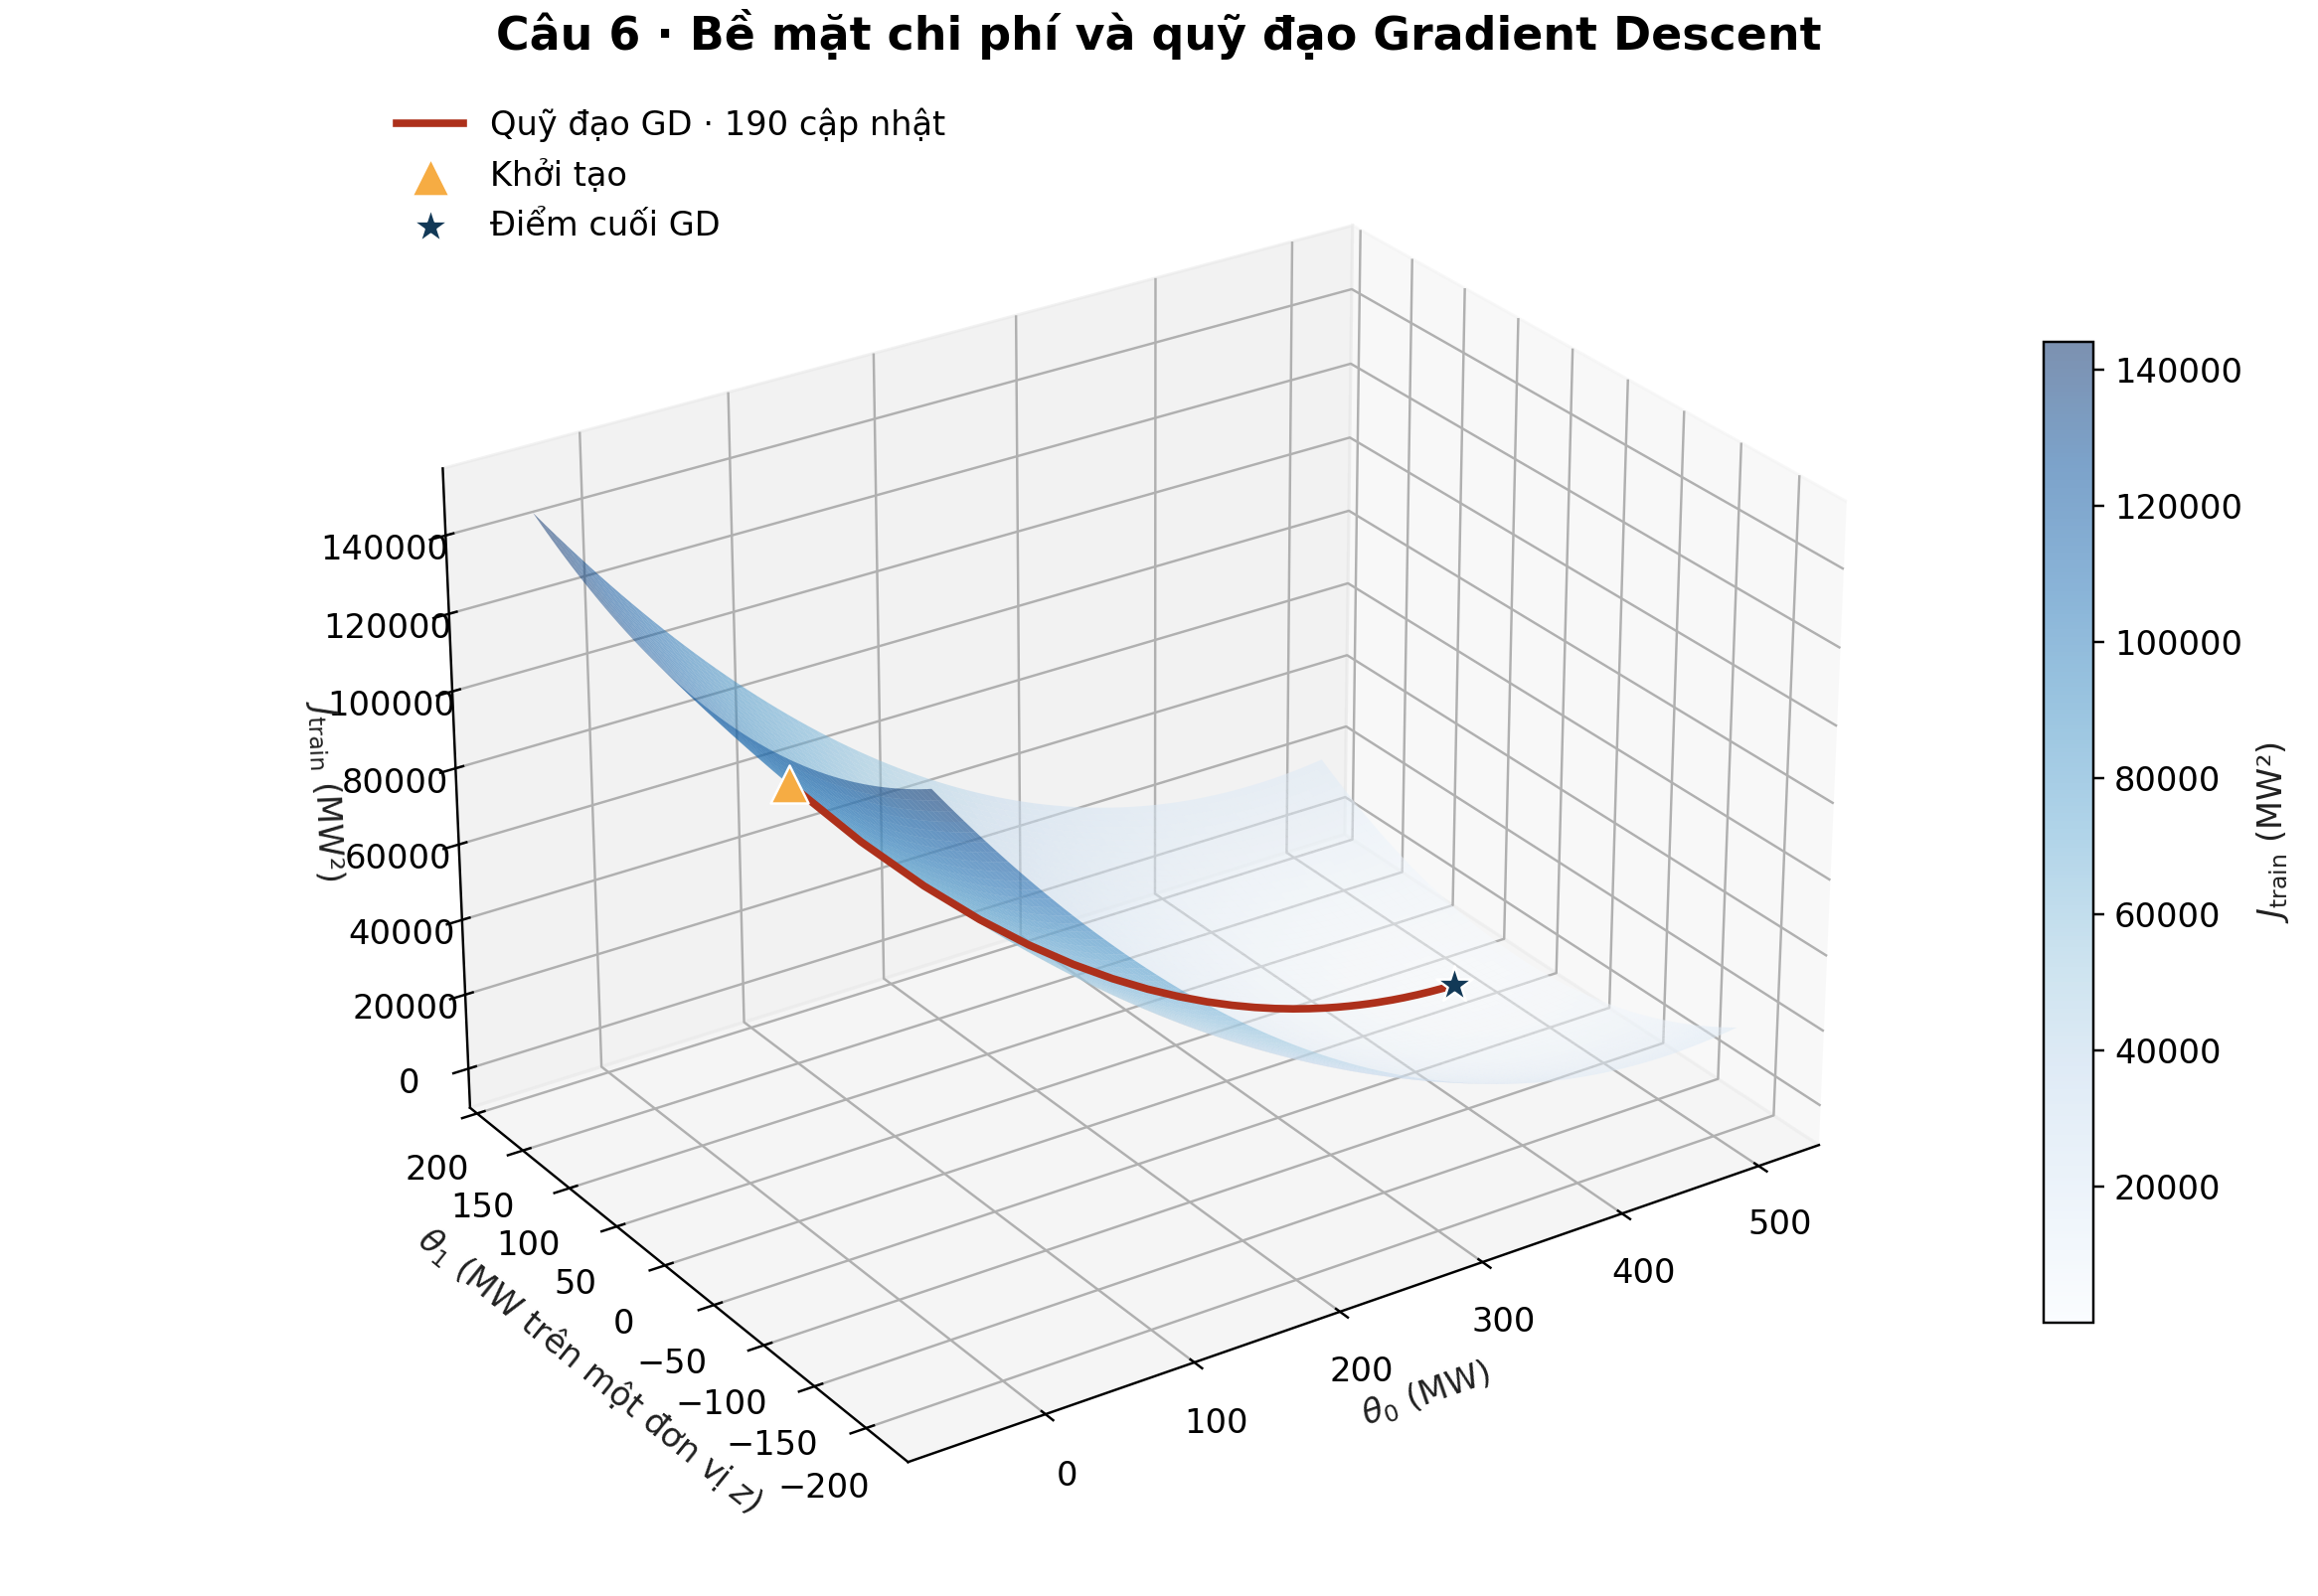

**Đường đồng mức và quỹ đạo GD**

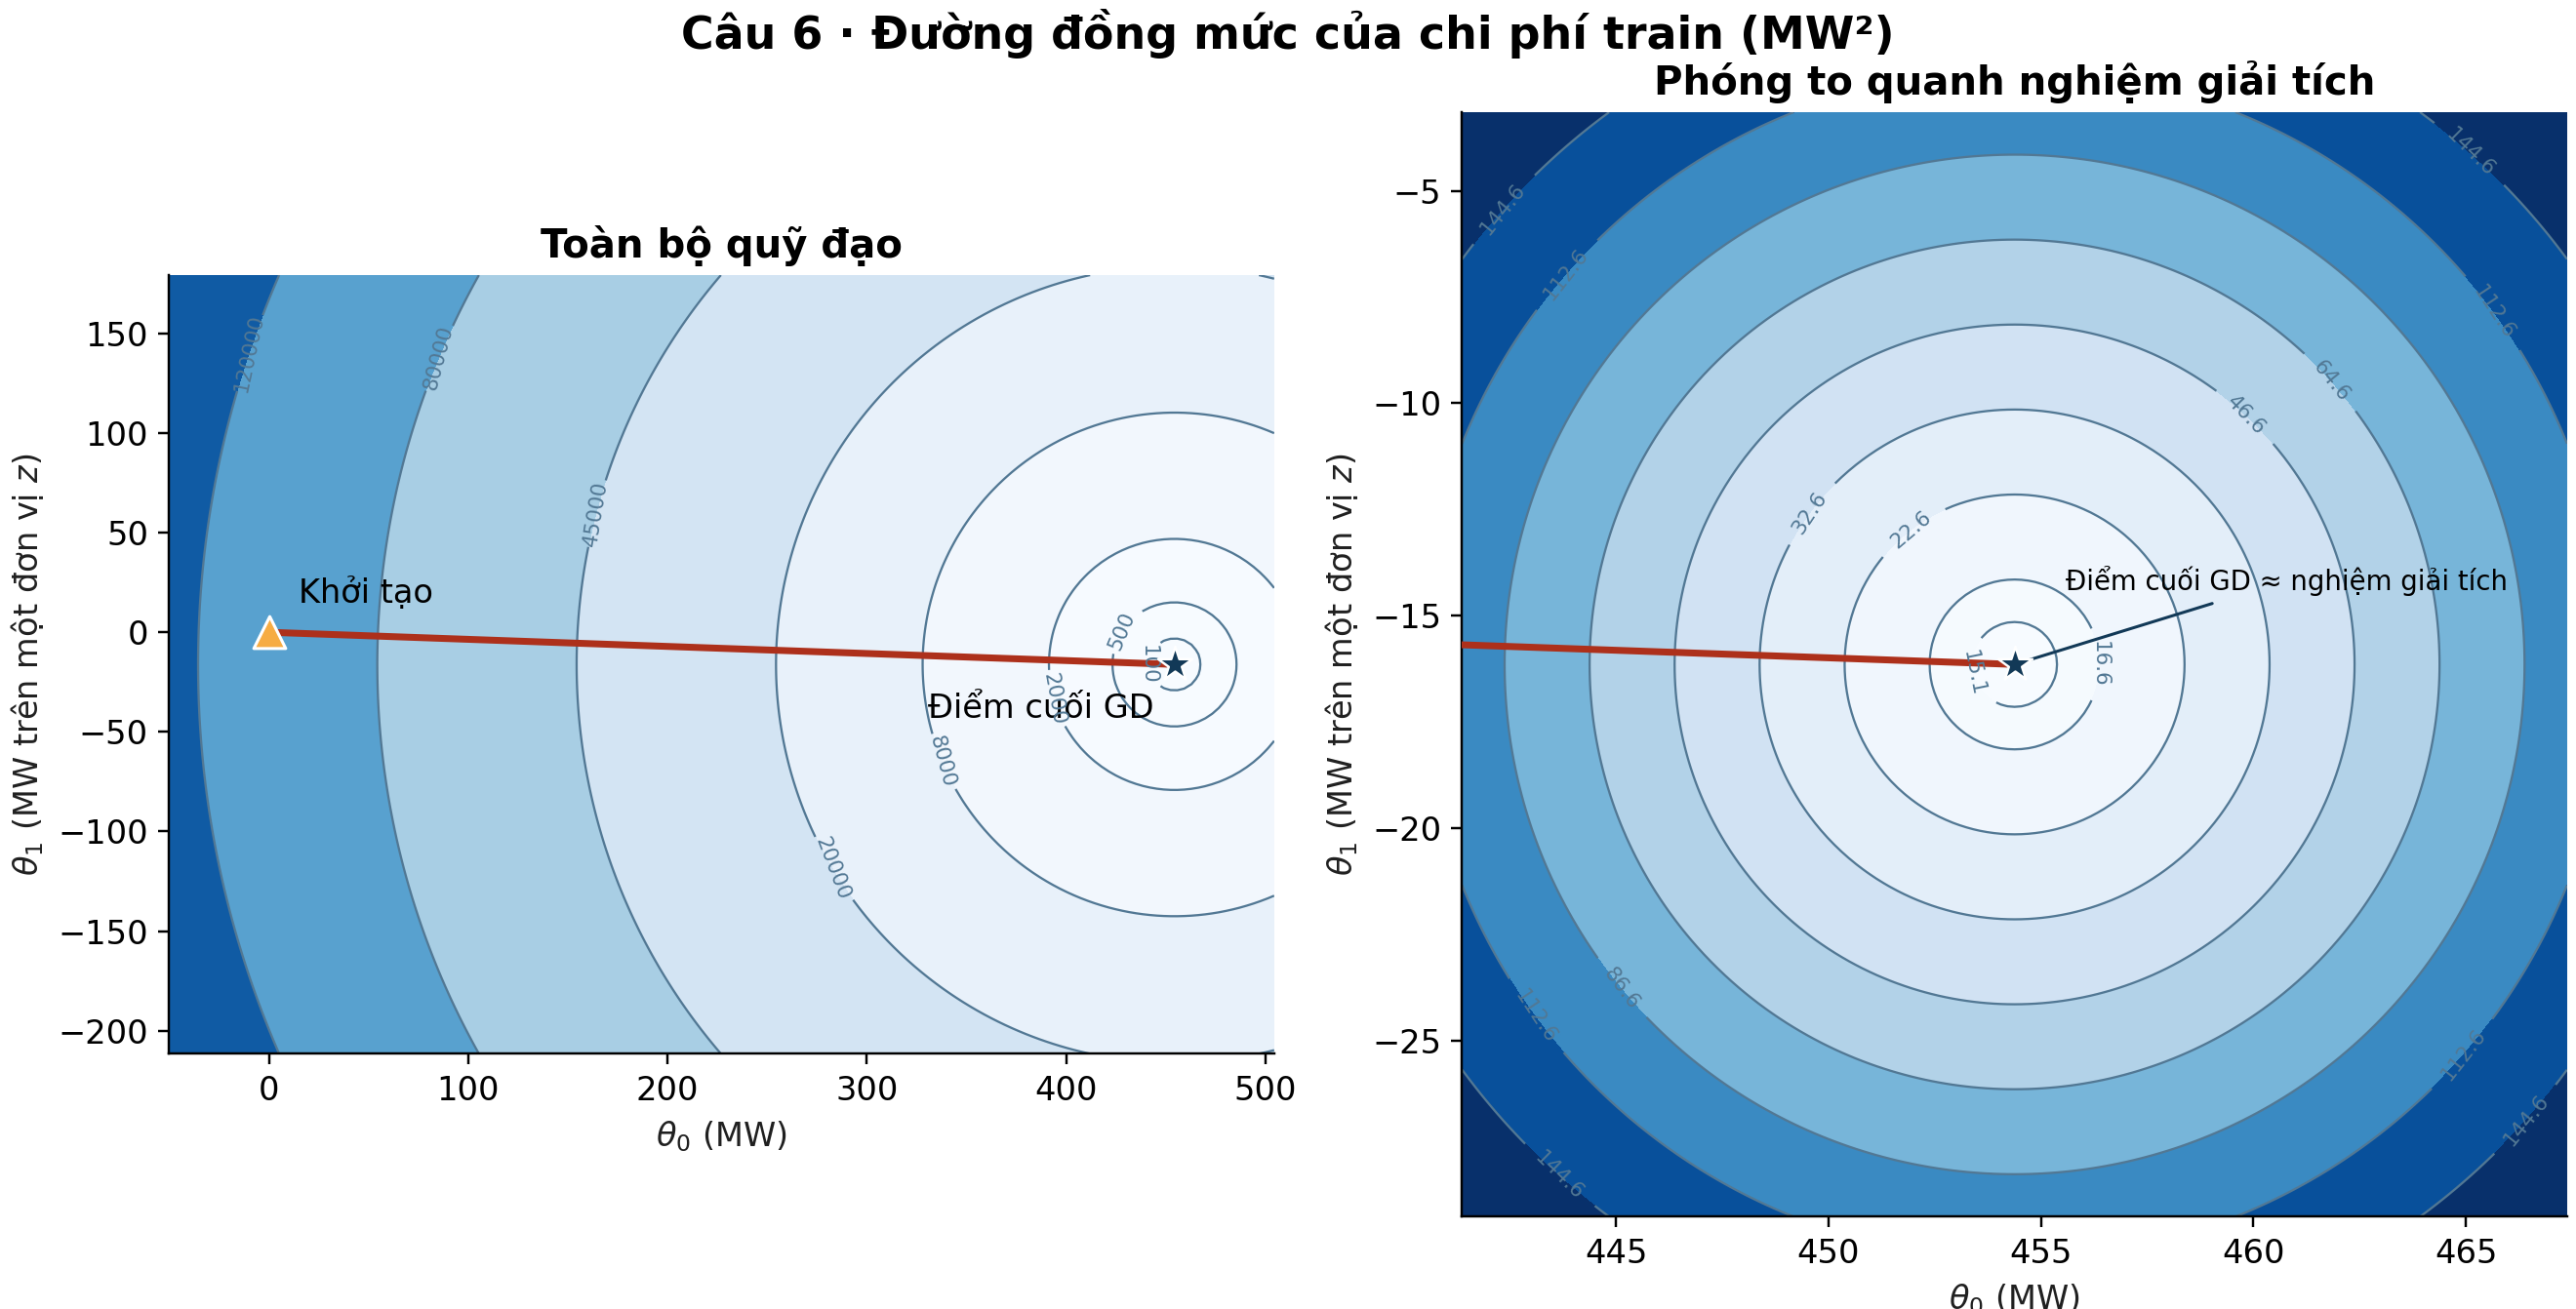

In [41]:
"""Plot the verified Q4 trajectory on the Q3 training cost landscape."""
import json

import matplotlib.pyplot as plt
import numpy as np


_nb_q6_visualization_PATH = '#ad301b'
_nb_q6_visualization_START = '#f6ac43'
_nb_q6_visualization_END = '#123957'


def _nb_q6_visualization_cost_landscape(parameters, optimum, j_star, gradient, hessian):
    """Evaluate the exact quadratic expansion of half-MSE around the reference."""
    delta = parameters - optimum
    return j_star + delta @ gradient + 0.5 * np.einsum(
        '...i,ij,...j->...', delta, hessian, delta
    )


def _nb_q6_visualization_make_grid(xlim, ylim, evaluate):
    x, y = np.meshgrid(np.linspace(*xlim, 161), np.linspace(*ylim, 161))
    return x, y, evaluate(np.stack((x, y), axis=-1))


def _nb_q6_visualization_plot_surface(grid, history, cost, output):
    fig = plt.figure(figsize=(10.6, 7.3), layout='constrained')
    ax = fig.add_subplot(projection='3d', computed_zorder=False)
    surface = ax.plot_surface(*grid, cmap='Blues', alpha=0.53,
                              linewidth=0, rcount=85, ccount=85, zorder=1)
    ax.plot(*history.T, cost, color=_nb_q6_visualization_PATH, linewidth=2.5, zorder=3,
            label=f'Quỹ đạo GD · {len(cost)-1} cập nhật')
    for index, color, marker, label in (
        (0, _nb_q6_visualization_START, '^', 'Khởi tạo'), (-1, _nb_q6_visualization_END, '*', 'Điểm cuối GD')
    ):
        ax.scatter(*history[index], cost[index], color=color, marker=marker,
                   edgecolors='white', linewidths=0.8, s=155, zorder=5, label=label)
    ax.set(xlabel=r'$\theta_0$ (MW)', ylabel=r'$\theta_1$ (MW trên một đơn vị $z$)',
           zlabel=r'$J_{\mathrm{train}}$ (MW²)')
    ax.view_init(elev=27, azim=-124)
    ax.set_box_aspect((1.25, 0.95, 0.82))
    fig.colorbar(surface, ax=ax, shrink=0.65, pad=0.09, label=r'$J_{\mathrm{train}}$ (MW²)')
    ax.legend(loc='upper left', frameon=False)
    fig.suptitle('Câu 6 · Bề mặt chi phí và quỹ đạo Gradient Descent',
                 fontsize=15, fontweight='bold')
    fig.savefig(output, dpi=220)
    plt.close(fig)


def _nb_q6_visualization_plot_contours(full_grid, zoom_grid, history, optimum, j_star, output):
    fig, (full, zoom) = plt.subplots(1, 2, figsize=(12, 6.1), layout='constrained')
    panels = (
        (full, full_grid, [100, 500, 2000, 8000, 20000, 45000, 80000, 120000, 180000],
         'Toàn bộ quỹ đạo'),
        (zoom, zoom_grid, j_star + np.array([0.5, 2, 8, 18, 32, 50, 72, 98, 130]),
         'Phóng to quanh nghiệm giải tích'),
    )
    for ax, (x, y, cost), levels, title in panels:
        ax.contourf(x, y, cost, levels=np.r_[j_star, levels], cmap='Blues', extend='max')
        contours = ax.contour(x, y, cost, levels=levels, colors='#527894', linewidths=0.75)
        ax.clabel(contours, fmt='%.0f' if ax is full else '%.1f', fontsize=7)
        ax.plot(*history.T, color=_nb_q6_visualization_PATH, linewidth=2.3, zorder=3)
        ax.scatter(*history[-1], color=_nb_q6_visualization_END, marker='*', s=145, edgecolors='white',
                   linewidths=0.8, zorder=5)
        ax.set(xlabel=r'$\theta_0$ (MW)', ylabel=r'$\theta_1$ (MW trên một đơn vị $z$)',
               xlim=(x.min(), x.max()), ylim=(y.min(), y.max()), title=title)
        ax.set_aspect('equal', adjustable='box')
        ax.ticklabel_format(useOffset=False, axis='both')
    full.scatter(*history[0], color=_nb_q6_visualization_START, marker='^', s=115, edgecolors='white', zorder=5)
    full.annotate('Khởi tạo', history[0], xytext=(10, 10), textcoords='offset points')
    full.annotate('Điểm cuối GD', history[-1], xytext=(-7, -18),
                  textcoords='offset points', ha='right')
    zoom.annotate('Điểm cuối GD ≈ nghiệm giải tích', optimum, xytext=(17, 25),
                  textcoords='offset points', fontsize=9,
                  arrowprops={'arrowstyle': '-', 'color': _nb_q6_visualization_END})
    fig.suptitle('Câu 6 · Đường đồng mức của chi phí train (MW²)',
                 fontsize=15, fontweight='bold')
    fig.savefig(output, dpi=220)
    plt.close(fig)


def _nb_q6_visualization_main():
    X, y, train, _ = _nb_data_io_load_training_data()
    results = ROOT / 'results'
    config = json.loads((results / 'baseline_config.json').read_text(encoding='utf-8'))
    q5 = json.loads((results / 'q5_summary.json').read_text(encoding='utf-8'))
    contract = json.loads((results / 'data_contract.json').read_text(encoding='utf-8'))
    if (config['is_mock_data'] or not config['converged']
            or config['data_version'] != q5['data_version']
            or config['data_version'] != contract['data_version']
            or config['train_sha256'] != contract['sha256']['data/processed/train.csv']
            or config['scaling_sha256'] != contract['sha256']['results/scaling.json']):
        raise ValueError('Expected Q4 and Q5 results on the verified training data.')
    with np.load(results / 'baseline_run.npz', allow_pickle=False) as run:
        history, costs = run['theta_history'], run['cost_history']
        np.testing.assert_array_equal(run['source_row_train'], train.source_row)
        np.testing.assert_array_equal(history[0], config['theta_initial'])
        np.testing.assert_array_equal(history[-1], run['theta_final'])
    states = config['n_iter'] + 1
    if history.shape != (states, 2) or costs.shape != (states,):
        raise ValueError('Expected one parameter pair and cost per saved state.')
    direct_costs = np.array([_nb_linear_model_compute_cost(X, y, theta) for theta in history])
    np.testing.assert_allclose(costs, direct_costs, rtol=1e-12, atol=1e-10)

    optimum = np.asarray(q5['theta_scaled'])
    j_star = _nb_linear_model_compute_cost(X, y, optimum)
    gradient = _nb_linear_model_compute_gradient(X, y, optimum)
    if np.linalg.norm(gradient) > 1e-9:
        raise ValueError('Q5 reference is not stationary on the verified training data.')
    hessian = X.T @ X / len(y)

    def evaluate(parameters):
        return _nb_q6_visualization_cost_landscape(parameters, optimum, j_star, gradient, hessian)

    np.testing.assert_allclose(evaluate(history), direct_costs, rtol=1e-12, atol=1e-10)
    span = np.ptp(history[:, 0])
    xlim = (history[:, 0].min() - 0.11 * span, history[:, 0].max() + 0.11 * span)
    ylim = (optimum[1] - 0.43 * span, optimum[1] + 0.43 * span)
    full_grid = _nb_q6_visualization_make_grid(xlim, ylim, evaluate)
    zoom_grid = _nb_q6_visualization_make_grid((optimum[0] - 13, optimum[0] + 13),
                          (optimum[1] - 13, optimum[1] + 13), evaluate)
    for x, y_grid, grid_cost in (full_grid, zoom_grid):
        for i, j in ((0, 0), (80, 80), (-1, -1)):
            point = np.array([x[i, j], y_grid[i, j]])
            np.testing.assert_allclose(grid_cost[i, j], _nb_linear_model_compute_cost(X, y, point),
                                       rtol=1e-12, atol=1e-10)

    _nb_q6_visualization_plot_surface(full_grid, history, costs, ROOT / 'figures/q6_surface.png')
    _nb_q6_visualization_plot_contours(full_grid, zoom_grid, history, optimum, j_star,
                  ROOT / 'figures/q6_contour.png')
    summary = {
        'data_version': config['data_version'],
        'n_train': len(train),
        'n_iter': config['n_iter'],
        'plotted_states': states,
        'theta_start': history[0].tolist(),
        'theta_final': history[-1].tolist(),
        'theta_analytical': optimum.tolist(),
        'j_start': float(costs[0]),
        'j_final': float(costs[-1]),
        'j_analytical': j_star,
        'max_abs_saved_vs_recomputed_cost': float(np.max(np.abs(costs - direct_costs))),
        'max_abs_surface_vs_recomputed_cost_on_path': float(
            np.max(np.abs(evaluate(history) - direct_costs))
        ),
        'verification': 'PASS',
    }
    (results / 'q6_summary.json').write_text(json.dumps(summary, indent=2) + '\n',
                                            encoding='utf-8')

_nb_q6_visualization_main()

_q6_summary = json.loads((ROOT / "results/q6_summary.json").read_text(encoding="utf-8"))
display(Markdown("### Kết quả câu 6 — Quỹ đạo tối ưu hóa"))
display(pd.DataFrame([
    {"Đại lượng": "Theta khởi tạo", "theta0": _q6_summary["theta_start"][0], "theta1": _q6_summary["theta_start"][1], "J_train (MW²)": _q6_summary["j_start"]},
    {"Đại lượng": "Theta cuối GD", "theta0": _q6_summary["theta_final"][0], "theta1": _q6_summary["theta_final"][1], "J_train (MW²)": _q6_summary["j_final"]},
    {"Đại lượng": "Nghiệm giải tích", "theta0": _q6_summary["theta_analytical"][0], "theta1": _q6_summary["theta_analytical"][1], "J_train (MW²)": _q6_summary["j_analytical"]},
]).round(9))
print(f"Số lần cập nhật GD: {_q6_summary['n_iter']}; số trạng thái: {_q6_summary['plotted_states']}.")
display(Markdown("**Bề mặt chi phí 3D và quỹ đạo GD**"))
display(Image(filename=str(ROOT / "figures/q6_surface.png")))
display(Markdown("**Đường đồng mức và quỹ đạo GD**"))
display(Image(filename=str(ROOT / "figures/q6_contour.png")))


## Câu 7 — Phân tích hội tụ

Phân tích lịch sử chi phí, khoảng cách đến nghiệm tối ưu và ảnh hưởng của learning rate; phân biệt trường hợp hội tụ, chậm và phân kỳ.

### Kết quả câu 7 — So sánh hội tụ theo learning rate

,run_id,learning_rate,n_iter,status,gradient_norm_final,J_initial,J_final,optimality_gap_final_MW2,theta0_sign_flips_first_12_updates
0,baseline,0.10,190,converged,9.200000e-07,103375.999083,1.459220e+01,0.000000e+00,0.0
1,small,0.01,1984,converged,9.950000e-07,103375.999083,1.459220e+01,0.000000e+00,0.0
2,large,1.85,123,converged,9.470000e-07,103375.999083,1.459220e+01,0.000000e+00,12.0
3,divergent,2.05,284,diverged,4.736474e+08,103375.999083,1.121709e+17,1.121709e+17,12.0
4,one_step,1.00,1,converged,0.000000e+00,103375.999083,1.459220e+01,0.000000e+00,NaN


Cận ổn định nghiêm ngặt: learning rate < 2.000000; đã đối chiếu 2587 trạng thái GD.


**Chi phí theo vòng lặp và khoảng cách tới tối ưu**

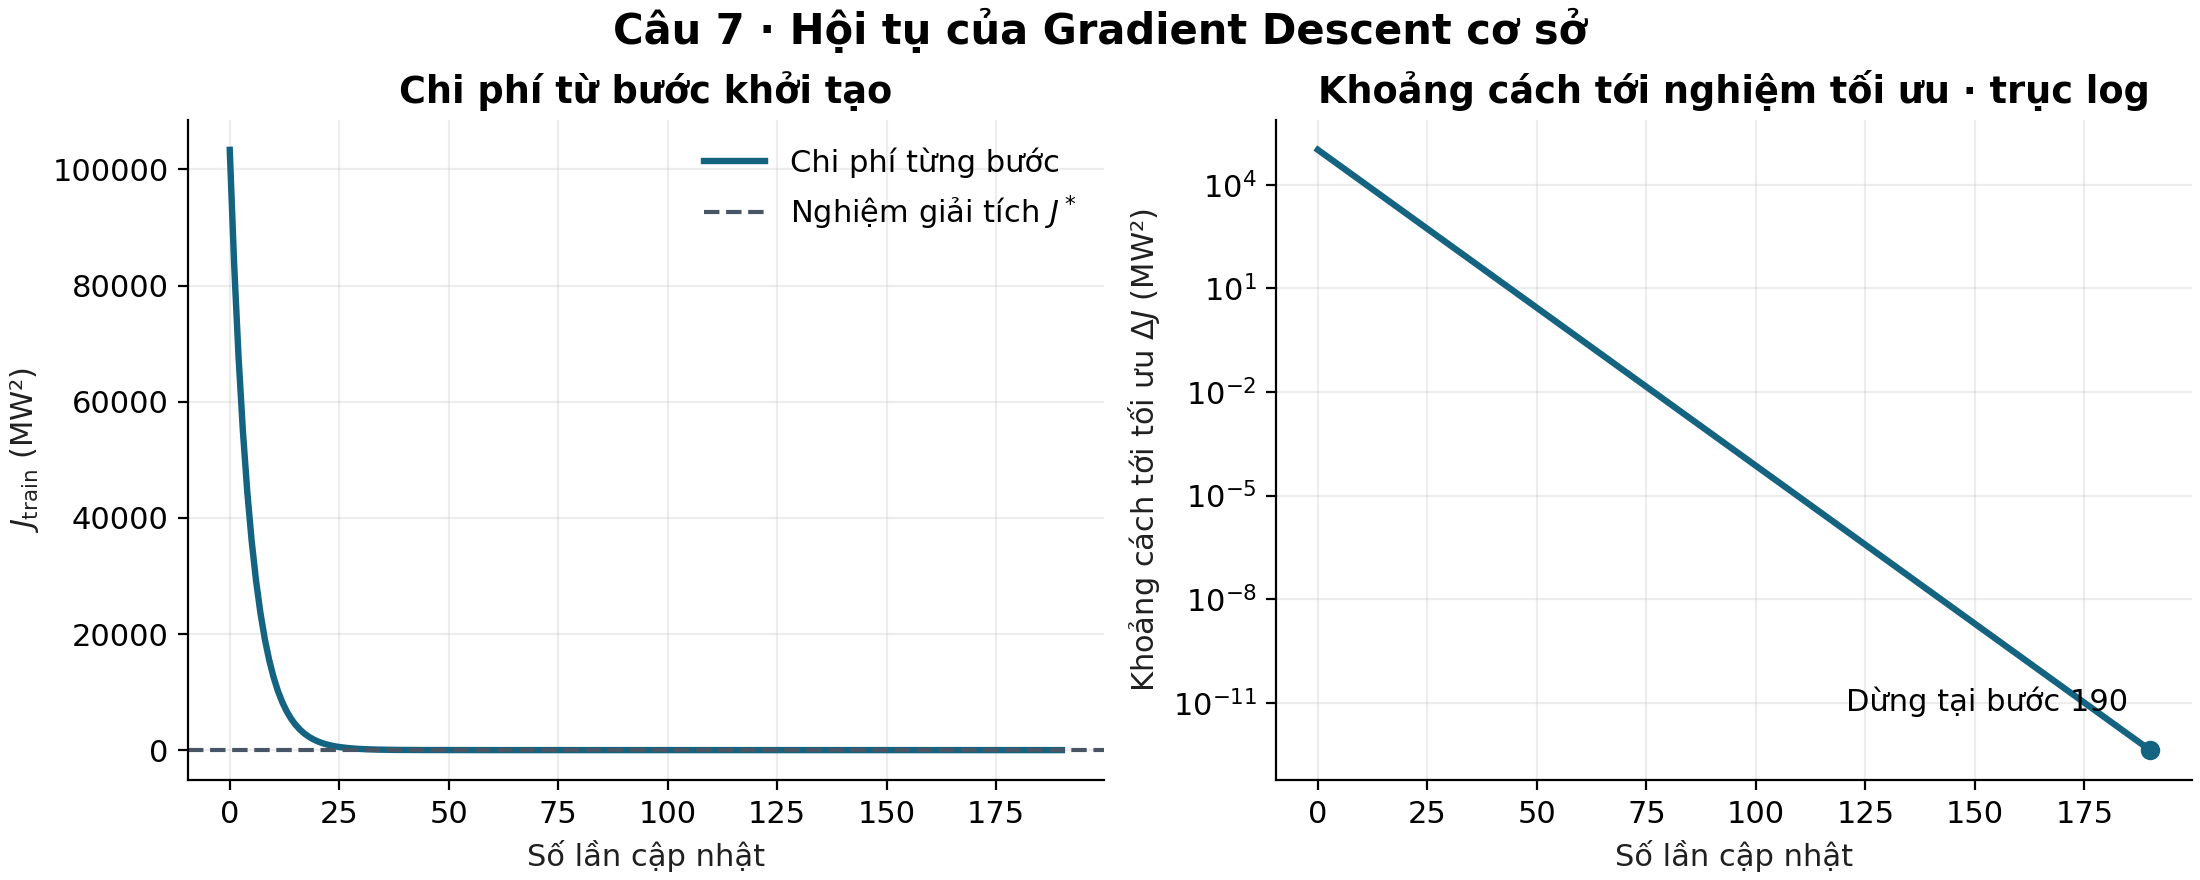

**Ảnh hưởng của learning rate lên quỹ đạo**

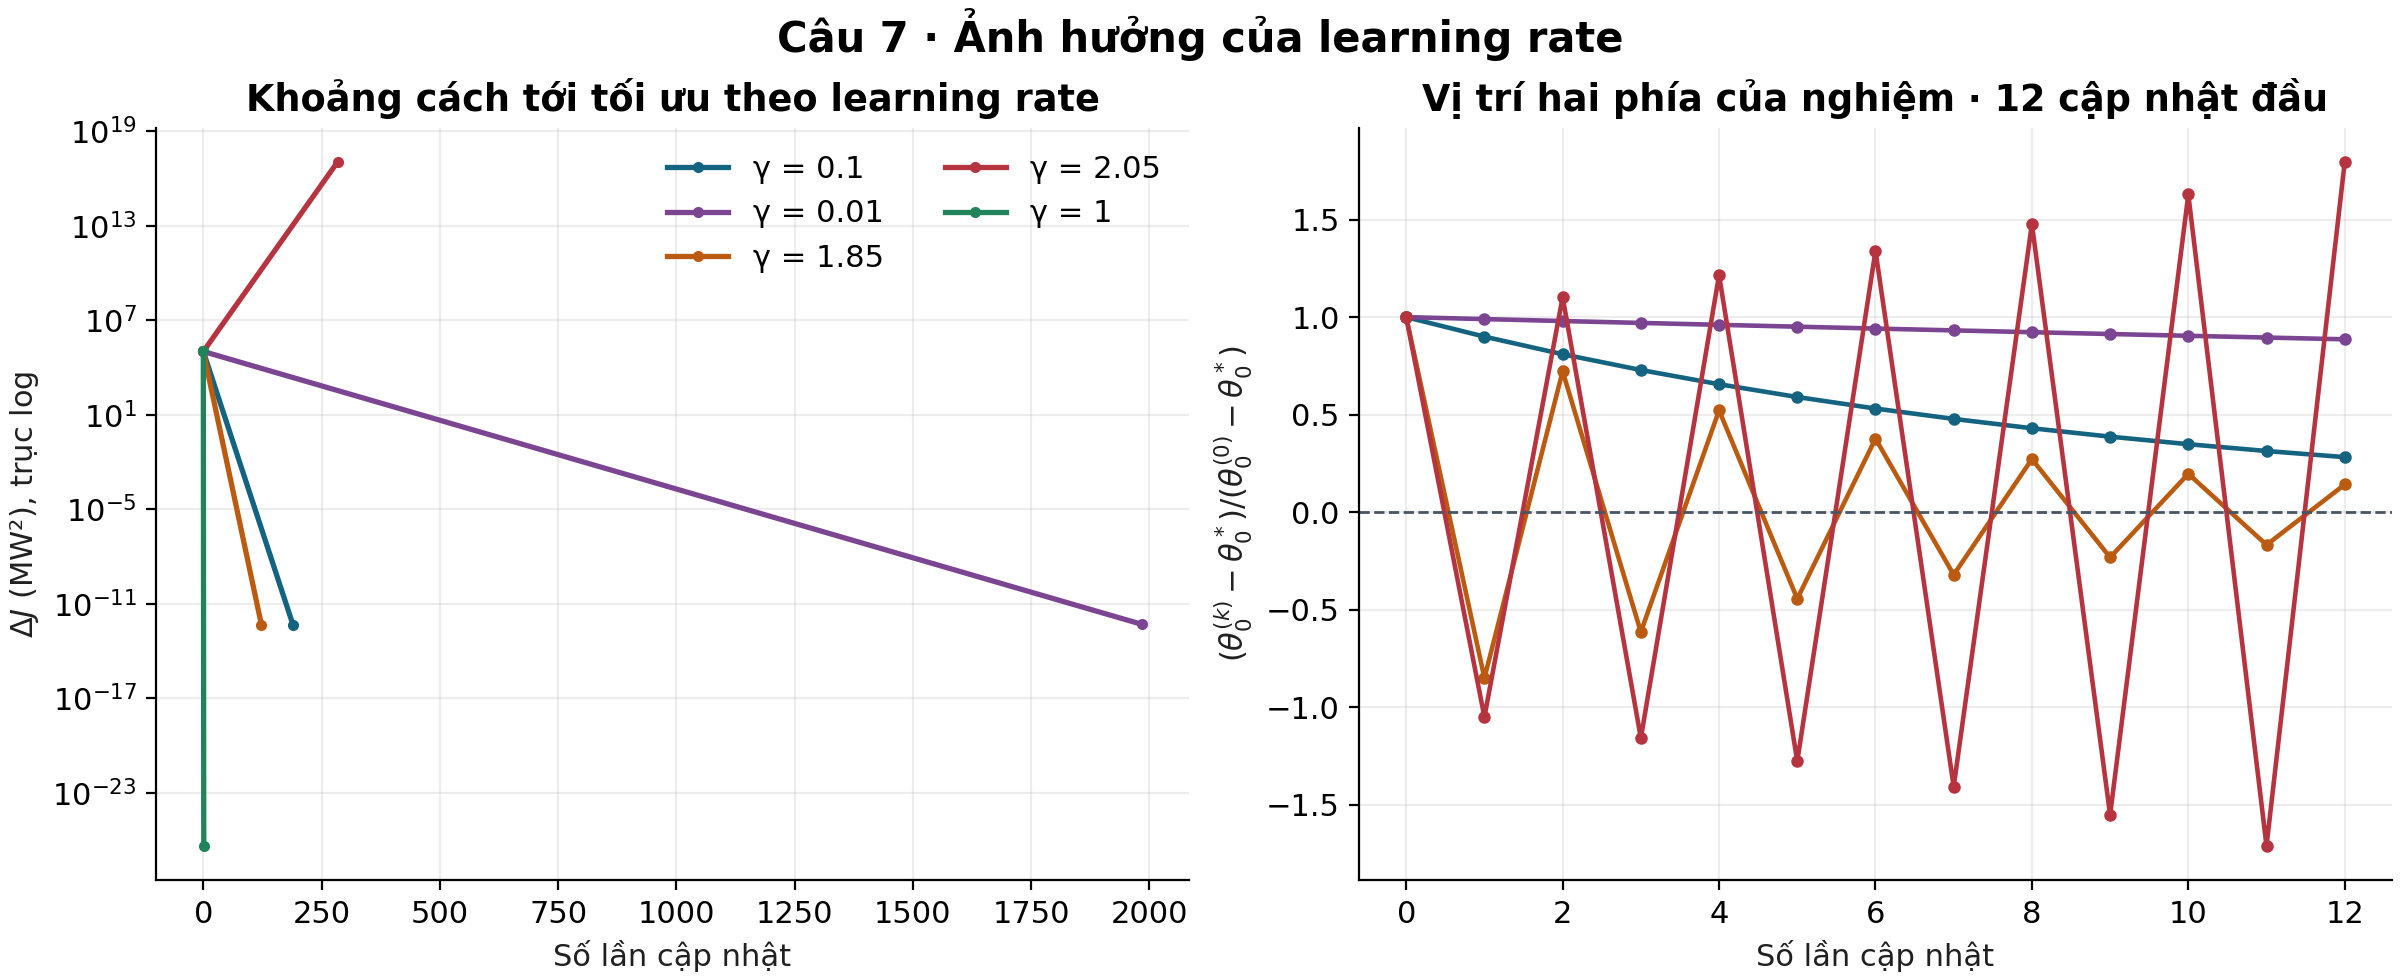

In [42]:
"""Analyze convergence using the verified Q4 train histories and Q5 optimum."""
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


_nb_q7_convergence_COLORS = {
    'small': '#7b4592',
    'baseline': '#146380',
    'large': '#ba5b11',
    'divergent': '#b63440',
    'one_step': '#218359',
}


def _nb_q7_convergence_plot_baseline(costs, gaps, j_star, output):
    k = np.arange(len(costs))
    fig, (cost_ax, gap_ax) = plt.subplots(1, 2, figsize=(11, 4.4), layout='constrained')
    color = _nb_q7_convergence_COLORS['baseline']
    cost_ax.plot(k, costs, color=color, linewidth=2.3, label='Chi phí từng bước')
    cost_ax.axhline(j_star, color='#485565', linestyle='--', label=r'Nghiệm giải tích $J^*$')
    cost_ax.legend(frameon=False)
    cost_ax.set(ylabel=r'$J_{\mathrm{train}}$ (MW²)', title='Chi phí từ bước khởi tạo')
    gap_ax.semilogy(k, np.where(gaps > 0, gaps, np.nan), color=color, linewidth=2.3)
    gap_ax.scatter(k[-1], gaps[-1], color=color, zorder=3)
    gap_ax.annotate(f'Dừng tại bước {k[-1]}', (k[-1], gaps[-1]),
                    xytext=(-8, 14), textcoords='offset points', ha='right')
    gap_ax.set(ylabel=r'Khoảng cách tới tối ưu $\Delta J$ (MW²)',
               title='Khoảng cách tới nghiệm tối ưu · trục log')
    for ax in (cost_ax, gap_ax):
        ax.set_xlabel('Số lần cập nhật')
        ax.grid(alpha=0.22)
    fig.suptitle('Câu 7 · Hội tụ của Gradient Descent cơ sở', fontsize=15, fontweight='bold')
    fig.savefig(output, dpi=200)
    plt.close(fig)


def _nb_q7_convergence_plot_learning_rates(traces, output):
    fig, (gap_ax, direction_ax) = plt.subplots(1, 2, figsize=(12, 4.9), layout='constrained')
    for run_id, (rate, gap, signed_error) in traces.items():
        color = _nb_q7_convergence_COLORS[run_id]
        gap_ax.semilogy(np.arange(len(gap)), np.where(gap > 0, gap, np.nan),
                        color=color, linewidth=1.9, label=f'γ = {rate:g}', marker='.',
                        markevery=[0, len(gap) - 1])
        if run_id != 'one_step':
            first = signed_error[:13]
            direction_ax.plot(np.arange(len(first)), first, color=color,
                              linewidth=1.65, marker='o', markersize=3.5)
    direction_ax.axhline(0, color='#485565', linestyle='--', linewidth=1)
    gap_ax.legend(frameon=False, ncol=2)
    gap_ax.set(title='Khoảng cách tới tối ưu theo learning rate',
               ylabel=r'$\Delta J$ (MW²), trục log')
    direction_ax.set(title='Vị trí hai phía của nghiệm · 12 cập nhật đầu',
                     ylabel=r'$(\theta_0^{(k)}-\theta_0^*) / (\theta_0^{(0)}-\theta_0^*)$',
                     xticks=np.arange(0, 13, 2))
    for ax in (gap_ax, direction_ax):
        ax.set_xlabel('Số lần cập nhật')
        ax.grid(alpha=0.22)
    fig.suptitle('Câu 7 · Ảnh hưởng của learning rate', fontsize=15, fontweight='bold')
    fig.savefig(output, dpi=200)
    plt.close(fig)


def _nb_q7_convergence_main():
    X, y, train, _ = _nb_data_io_load_training_data()
    results = ROOT / 'results'
    config = json.loads((results / 'baseline_config.json').read_text(encoding='utf-8'))
    q5 = json.loads((results / 'q5_summary.json').read_text(encoding='utf-8'))
    contract = json.loads((results / 'data_contract.json').read_text(encoding='utf-8'))
    if (config['is_mock_data'] or not config['converged']
            or config['data_version'] != q5['data_version']
            or config['data_version'] != contract['data_version']
            or config['train_sha256'] != contract['sha256']['data/processed/train.csv']
            or config['scaling_sha256'] != contract['sha256']['results/scaling.json']):
        raise ValueError('Expected Q4 and Q5 results on the verified train split.')

    optimum = np.array(q5['theta_scaled'])
    j_star = _nb_linear_model_compute_cost(X, y, optimum)
    hessian = X.T @ X / len(y)
    eigenvalues = np.linalg.eigvalsh(hessian)
    if np.linalg.norm(_nb_linear_model_compute_gradient(X, y, optimum)) > 1e-9:
        raise ValueError('Q5 reference fails the stationary-point check.')

    profiles = pd.read_csv(results / 'q4_learning_rate_runs.csv').set_index('run_id')
    traces = {}
    rows = []
    for run_id, spec in config['experiment_runs'].items():
        rate, steps, status = spec['learning_rate'], spec['n_iter'], spec['status']
        profile = profiles.loc[run_id]
        np.testing.assert_allclose(
            [profile.learning_rate, profile.n_iter, profile.max_iter,
             profile.tolerance_gradient_l2, profile.theta0_initial, profile.theta1_initial],
            [rate, steps, config['max_iter'], config['tolerance'], *config['theta_initial']],
        )
        if profile.status != status or profile.split != 'train':
            raise ValueError(f'{run_id}: inconsistent Q4 metadata.')
        with np.load(results / f'q4_{run_id}_history.npz', allow_pickle=False) as run:
            history, costs = run['theta_history'], run['cost_history']
            np.testing.assert_array_equal(history[-1], run['theta_final'])
            if (run['learning_rate'].item(), run['n_iter'].item(), run['status'].item()) != (
                rate, steps, status
            ):
                raise ValueError(f'{run_id}: history metadata mismatch.')
        if history.shape != (steps + 1, 2) or costs.shape != (steps + 1,):
            raise ValueError(f'{run_id}: inconsistent history length.')
        np.testing.assert_array_equal(history[0], config['theta_initial'])
        gradients = np.array([_nb_linear_model_compute_gradient(X, y, theta) for theta in history])
        direct_costs = np.array([_nb_linear_model_compute_cost(X, y, theta) for theta in history])
        np.testing.assert_allclose(costs, direct_costs, atol=1e-10, rtol=1e-12)
        np.testing.assert_allclose(history[1:], history[:-1] - rate * gradients[:-1],
                                   atol=1e-10, rtol=1e-12)
        norms = np.linalg.norm(gradients, axis=1)
        if status == 'converged':
            if norms[-1] > config['tolerance'] or np.any(norms[:-1] <= config['tolerance']):
                raise ValueError(f'{run_id}: inconsistent gradient stopping criterion.')
        else:
            threshold = 1e12 * max(costs[0], 1)
            if status != 'diverged' or costs[-1] <= threshold or np.any(costs[:-1] > threshold):
                raise ValueError(f'{run_id}: inconsistent divergence stopping criterion.')

        delta = history - optimum
        # Quadratic optimality gap avoids cancellation in J(theta) - J*.
        gaps = 0.5 * np.einsum('ki,ij,kj->k', delta, hessian, delta)
        np.testing.assert_allclose(costs, j_star + gaps, atol=1e-10, rtol=1e-12)
        signed_error = delta[:, 0] / delta[0, 0]
        traces[run_id] = (rate, gaps, signed_error)
        rows.append({
            'run_id': run_id, 'learning_rate': rate, 'n_train': len(train),
            'theta0_initial': history[0, 0], 'theta1_initial': history[0, 1],
            'max_iter': config['max_iter'], 'gradient_tolerance': config['tolerance'],
            'n_iter': steps, 'status': status, 'stop_reason': profile.stop_reason,
            'gradient_norm_final': norms[-1], 'J_initial': costs[0], 'J_final': costs[-1],
            'J_analytical': j_star, 'optimality_gap_final_MW2': gaps[-1],
            'theta0_sign_flips_first_12_updates': int(np.count_nonzero(
                np.signbit(signed_error[1:13]) != np.signbit(signed_error[:12])
            )) if run_id != 'one_step' else None,
        })
        if run_id == 'baseline':
            with np.load(results / 'baseline_run.npz', allow_pickle=False) as baseline:
                np.testing.assert_array_equal(baseline['source_row_train'], train.source_row)
                np.testing.assert_array_equal(history, baseline['theta_history'])
                np.testing.assert_array_equal(costs, baseline['cost_history'])
            _nb_q7_convergence_plot_baseline(costs, gaps, j_star, ROOT / 'figures/q7_convergence.png')

    _nb_q7_convergence_plot_learning_rates(traces, ROOT / 'figures/q7_learning_rate.png')
    runs = pd.DataFrame(rows)
    runs['theta0_sign_flips_first_12_updates'] = runs[
        'theta0_sign_flips_first_12_updates'
    ].astype('Int64')
    runs.to_csv(results / 'q7_runs.csv', index=False)
    summary = {
        'data_version': config['data_version'], 'n_train': len(train), 'split': 'train',
        'hessian_eigenvalues': eigenvalues.tolist(),
        'strict_stability_upper_bound': float(2 / eigenvalues[-1]),
        'j_analytical': j_star, 'runs_verified': len(rows),
        'states_verified': sum(row['n_iter'] + 1 for row in rows),
        'verification': 'PASS',
    }
    (results / 'q7_summary.json').write_text(json.dumps(summary, indent=2) + '\n',
                                            encoding='utf-8')

_nb_q7_convergence_main()

_q7_runs = pd.read_csv(ROOT / "results/q7_runs.csv")
_q7_summary = json.loads((ROOT / "results/q7_summary.json").read_text(encoding="utf-8"))
display(Markdown("### Kết quả câu 7 — So sánh hội tụ theo learning rate"))
display(_q7_runs[["run_id", "learning_rate", "n_iter", "status", "gradient_norm_final", "J_initial", "J_final", "optimality_gap_final_MW2", "theta0_sign_flips_first_12_updates"]].round(9))
print(f"Cận ổn định nghiêm ngặt: learning rate < {_q7_summary['strict_stability_upper_bound']:.6f}; đã đối chiếu {_q7_summary['states_verified']} trạng thái GD.")
display(Markdown("**Chi phí theo vòng lặp và khoảng cách tới tối ưu**"))
display(Image(filename=str(ROOT / "figures/q7_convergence.png")))
display(Markdown("**Ảnh hưởng của learning rate lên quỹ đạo**"))
display(Image(filename=str(ROOT / "figures/q7_learning_rate.png")))


## Câu 8 — Dự đoán, đánh giá và phân tích phần dư

Dùng baseline đã chốt để dự đoán, báo cáo MSE và R², vẽ đường hồi quy trên quan sát và phân tích phần dư theo định nghĩa `e = y − ŷ`.

### Kết quả câu 8 — Đánh giá mô hình và phần dư

**Chỉ số trên train và test**

,split,n_observations,MSE_MW2,RMSE_MW,R2,residual_mean_MW,residual_std_MW
0,train,7622,29.184401,5.402259,0.899372,0.000001,5.402259
1,test,1905,30.547660,5.526994,0.895159,0.050330,5.526765


**Dự đoán PE tại một số nhiệt độ AT**

,AT_degC,AT_scaled,PE_predicted_MW
0,10.0,-1.294097,475.281143
1,20.0,0.049322,453.584301
2,30.0,1.392740,431.887460


**Thống kê phần dư theo nhóm giá trị dự đoán**

,split,bin,n,mean_predicted_MW,mean_AT_degC,mean_residual_MW,residual_std_MW,min_residual_MW,max_residual_MW
0,test,1,207,429.381003,31.155217,4.085277,5.045875,-6.115763,23.254510
1,test,2,180,436.527329,27.861500,0.473171,5.443439,-11.348639,14.884936
2,test,3,188,441.306543,25.658777,-1.633512,5.543226,-15.182849,13.432469
3,test,4,206,445.419022,23.763350,-2.744410,4.790802,-19.663619,11.858124
4,test,5,195,450.056061,21.626154,-2.410882,5.300042,-16.542941,12.538936
5,test,6,176,455.980323,18.895682,-0.853902,5.000644,-14.275072,12.664090
6,test,7,190,462.571704,15.857737,-0.068388,5.128426,-30.985324,12.930945
7,test,8,179,467.845429,13.427095,1.233174,4.193084,-16.147791,10.223611
8,test,9,201,473.694467,10.731294,1.039912,4.787993,-22.721888,18.043813
9,test,10,183,481.057838,7.337541,1.317736,6.111588,-45.906439,14.822929


Mô hình: PE_hat = 496.977984 -2.169684 × AT; J_train = 14.592200 MW². Có 9,527 dự đoán.


**Đường hồi quy trên quan sát**

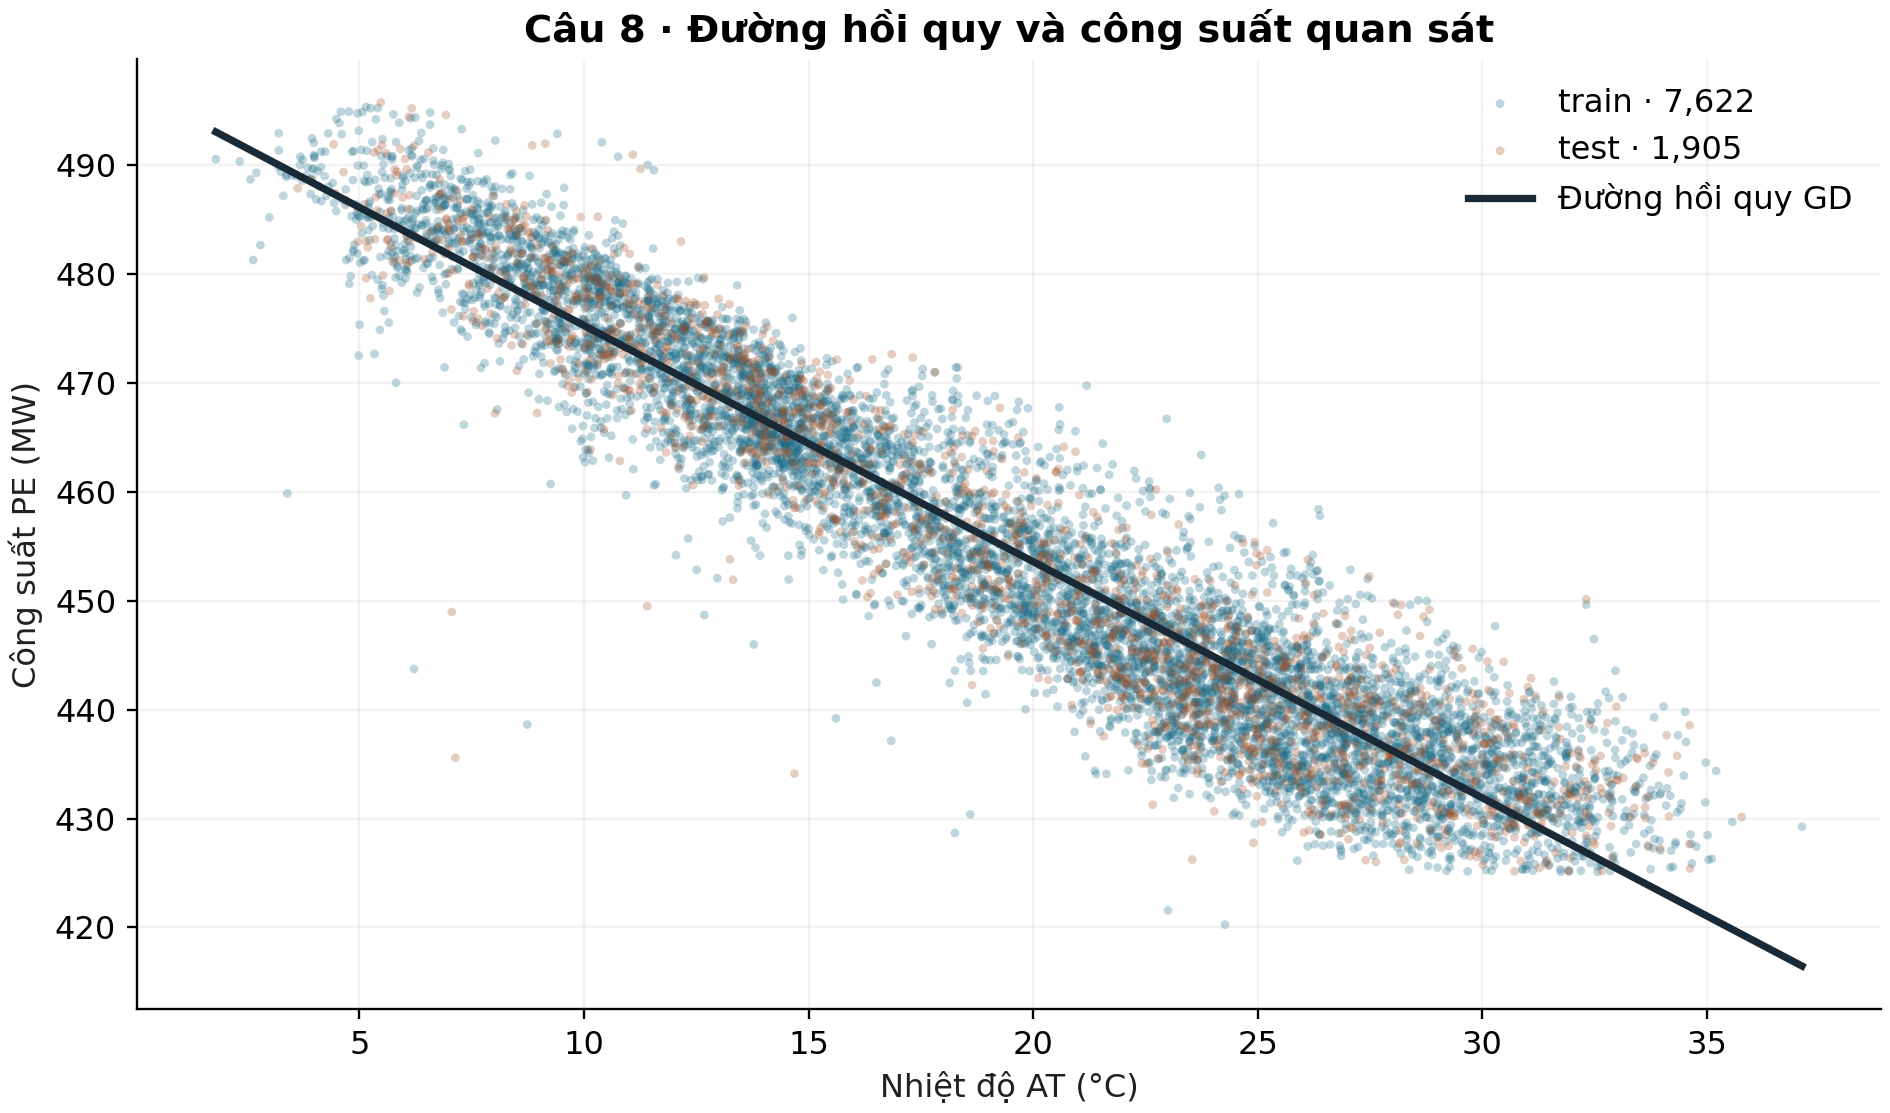

**Phần dư trên train**

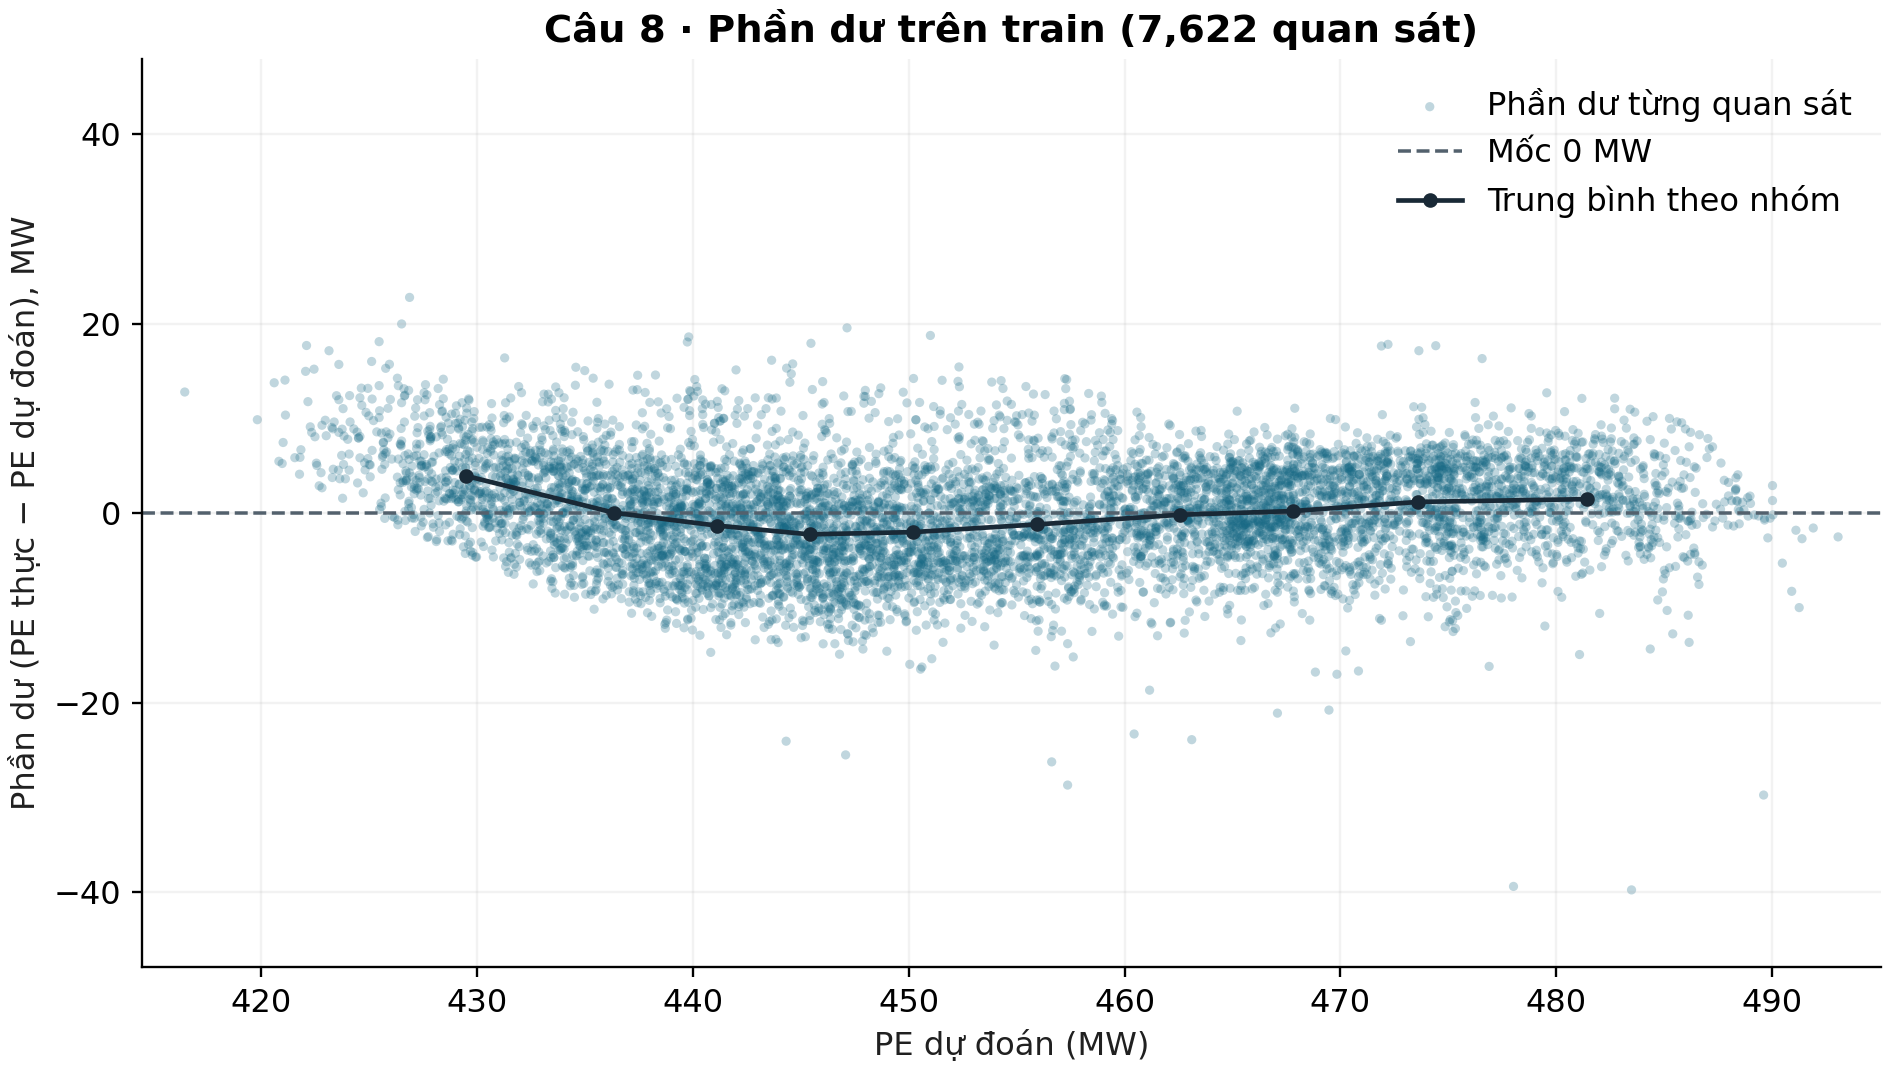

**Phần dư trên test**

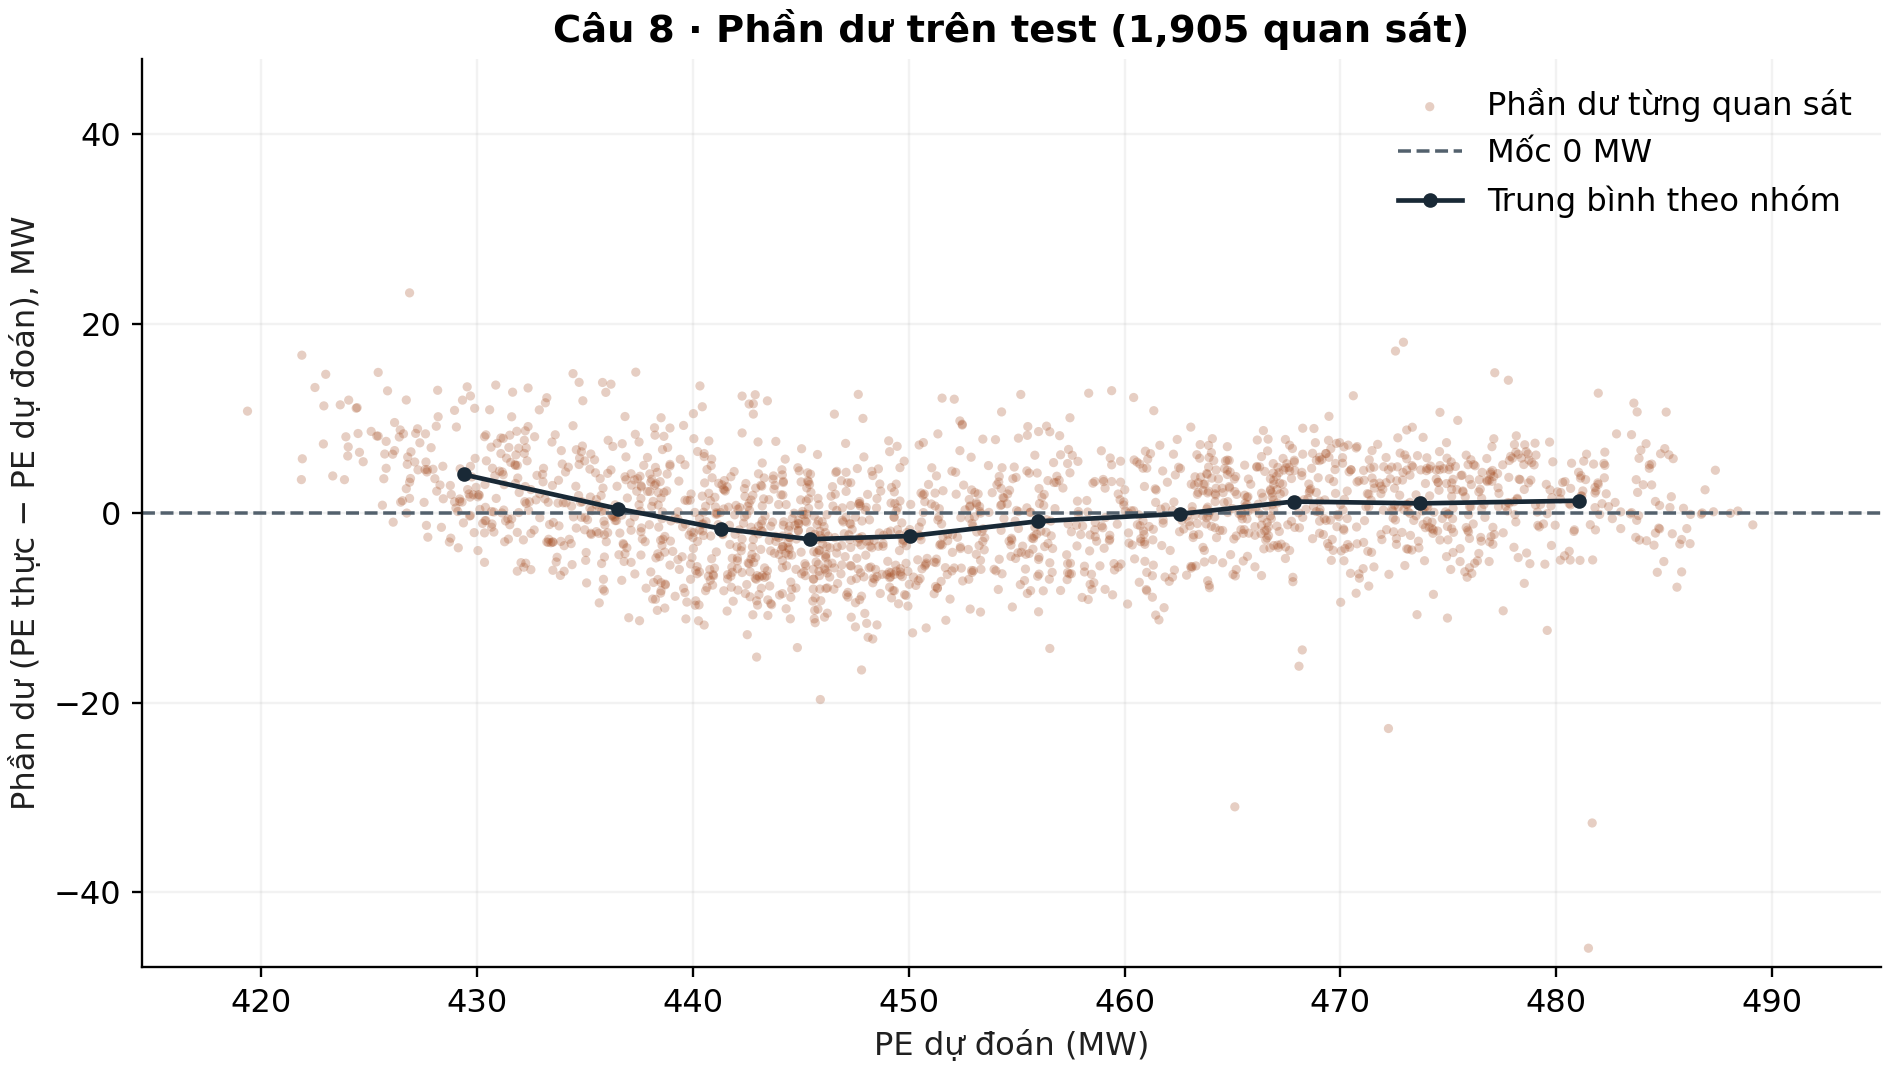

In [43]:
"""Evaluation of the locked Q4 model for Q8, with shared NumPy metrics."""
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


_nb_evaluate_COLORS = {'train': '#176985', 'test': '#a44d22'}


def _nb_evaluate_evaluate_split(split, frame, predictions):
    actual = frame.PE.to_numpy(dtype=float)
    scores = _nb_reference_metrics(actual, predictions)
    residuals = actual - predictions
    rows = pd.DataFrame({
        'source_row': frame.source_row, 'split': split, 'AT_degC': frame.AT,
        'PE_actual_MW': actual, 'PE_predicted_MW': predictions, 'residual_MW': residuals,
    })
    return {
        'split': split, 'n_observations': len(actual), 'MSE_MW2': scores['MSE'],
        'RMSE_MW': scores['RMSE'], 'R2': scores['R2'],
        'residual_mean_MW': float(residuals.mean()),
        'residual_std_MW': float(residuals.std()),
    }, rows


def _nb_evaluate_residual_groups(rows, edges):
    groups = pd.cut(rows.PE_predicted_MW, bins=edges, labels=False)
    return (rows.assign(bin=groups + 1).groupby(['split', 'bin'], sort=False)
            .agg(n=('residual_MW', 'size'),
                 mean_predicted_MW=('PE_predicted_MW', 'mean'),
                 mean_AT_degC=('AT_degC', 'mean'),
                 mean_residual_MW=('residual_MW', 'mean'),
                 residual_std_MW=('residual_MW', lambda values: values.std(ddof=0)),
                 min_residual_MW=('residual_MW', 'min'),
                 max_residual_MW=('residual_MW', 'max'))
            .sort_index().reset_index())


def _nb_evaluate_plot_fit(rows, theta_raw, output):
    fig, ax = plt.subplots(figsize=(9, 5.3), layout='constrained')
    for split, data in rows.groupby('split', sort=False):
        ax.scatter(data.AT_degC, data.PE_actual_MW, s=9, alpha=0.28,
                   color=_nb_evaluate_COLORS[split], edgecolors='none', label=f'{split} · {len(data):,}')
    at = np.sort(rows.AT_degC.unique())
    ax.plot(at, theta_raw[0] + theta_raw[1] * at, color='#192936',
            linewidth=2.5, label='Đường hồi quy GD')
    ax.set(xlabel='Nhiệt độ AT (°C)', ylabel='Công suất PE (MW)',
           title='Câu 8 · Đường hồi quy và công suất quan sát')
    ax.legend(frameon=False)
    ax.grid(alpha=0.16)
    fig.savefig(output, dpi=210)
    plt.close(fig)


def _nb_evaluate_plot_residuals(split, rows, bins, xlim, ylim, output):
    fig, ax = plt.subplots(figsize=(9, 5.1), layout='constrained')
    ax.scatter(rows.PE_predicted_MW, rows.residual_MW, s=10, alpha=0.27,
               color=_nb_evaluate_COLORS[split], edgecolors='none', label='Phần dư từng quan sát')
    ax.axhline(0, color='#53616d', linewidth=1.2, linestyle='--', label='Mốc 0 MW')
    ax.plot(bins.mean_predicted_MW, bins.mean_residual_MW, color='#192936',
            marker='o', markersize=4, linewidth=1.6, label='Trung bình theo nhóm')
    ax.set(xlabel='PE dự đoán (MW)', ylabel='Phần dư (PE thực − PE dự đoán), MW',
           title=f'Câu 8 · Phần dư trên {split} ({len(rows):,} quan sát)',
           xlim=xlim, ylim=ylim)
    ax.legend(frameon=False, loc='upper right')
    ax.grid(alpha=0.16)
    fig.savefig(output, dpi=210)
    plt.close(fig)


def _nb_evaluate_main():
    X_train, y_train, train, scaling = _nb_data_io_load_training_data()
    results = ROOT / 'results'
    config = json.loads((results / 'baseline_config.json').read_text(encoding='utf-8'))
    contract = json.loads((results / 'data_contract.json').read_text(encoding='utf-8'))
    expected_inputs = {
        'train_sha256': 'data/processed/train.csv',
        'test_sha256': 'data/processed/test.csv',
        'scaling_sha256': 'results/scaling.json',
    }
    if (config['is_mock_data'] or not config['converged']
            or config['data_version'] != contract['data_version']
            or any(config[key] != contract['sha256'][name]
                   for key, name in expected_inputs.items())):
        raise ValueError('Q4 baseline does not match the verified data contract.')

    test = pd.read_csv(ROOT / 'data/processed/test.csv')
    if (len(test) != contract['n_test'] or not test.source_row.is_unique
            or not set(test.source_row).isdisjoint(train.source_row)):
        raise ValueError('Unexpected or overlapping test rows.')
    X_test = _nb_data_io_design_matrix(test.AT.to_numpy(), scaling)
    np.testing.assert_allclose(X_test[:, 1], test.AT_scaled, atol=1e-12, rtol=0)

    scores, row_frames = [], []
    with np.load(results / 'baseline_run.npz', allow_pickle=False) as baseline:
        theta = baseline['theta_final']
        np.testing.assert_array_equal(theta, baseline['theta_history'][-1])
        j_train = _nb_linear_model_compute_cost(X_train, y_train, theta)
        np.testing.assert_allclose(j_train, baseline['cost_history'][-1], atol=1e-10, rtol=0)
        for split, frame, design in (('train', train, X_train), ('test', test, X_test)):
            np.testing.assert_array_equal(frame.source_row, baseline[f'source_row_{split}'])
            pred = _nb_linear_model_predict(design, theta)
            np.testing.assert_allclose(pred, baseline[f'pred_{split}'], atol=1e-9, rtol=0)
            score, rows = _nb_evaluate_evaluate_split(split, frame, pred)
            scores.append(score)
            row_frames.append(rows)

    mse_gap = abs(scores[0]['MSE_MW2'] - 2 * j_train)
    np.testing.assert_allclose(mse_gap, 0, atol=1e-10, rtol=0)
    theta_raw = _nb_analytical_to_raw_scale(theta, scaling)
    predictions = pd.concat(row_frames, ignore_index=True)
    np.testing.assert_allclose(predictions.PE_predicted_MW,
                               theta_raw[0] + theta_raw[1] * predictions.AT_degC,
                               atol=1e-10, rtol=0)
    temperatures = np.array([10., 20., 30.])
    if temperatures.min() < train.AT.min() or temperatures.max() > train.AT.max():
        raise ValueError('Inference examples must lie inside the observed train range.')
    X_examples = _nb_data_io_design_matrix(temperatures, scaling)
    examples = pd.DataFrame({
        'AT_degC': temperatures,
        'AT_scaled': X_examples[:, 1],
        'PE_predicted_MW': _nb_linear_model_predict(X_examples, theta),
    })
    cuts = np.quantile(row_frames[0].PE_predicted_MW, np.arange(1, 10) / 10)
    bins = _nb_evaluate_residual_groups(predictions, np.r_[-np.inf, cuts, np.inf])
    np.testing.assert_array_equal(bins.groupby('split').n.sum().sort_index(),
                                  predictions.groupby('split').size().sort_index())

    pd.DataFrame(scores).to_csv(results / 'q8_metrics.csv', index=False)
    predictions.to_csv(results / 'q8_predictions.csv', index=False)
    examples.to_csv(results / 'q8_examples.csv', index=False)
    bins.to_csv(results / 'q8_residual_bins.csv', index=False)

    _nb_evaluate_plot_fit(predictions, theta_raw, ROOT / 'figures/q8_fit.png')
    xlim = (predictions.PE_predicted_MW.min() - 2, predictions.PE_predicted_MW.max() + 2)
    limit = float(predictions.residual_MW.abs().max() + 2)
    for split, rows in zip(('train', 'test'), row_frames):
        _nb_evaluate_plot_residuals(split, rows, bins[bins.split == split], xlim, (-limit, limit),
                       ROOT / f'figures/q8_residual_{split}.png')

    summary = {
        'data_version': config['data_version'], 'theta_scaled': theta.tolist(),
        'theta_raw': theta_raw.tolist(), 'J_train': j_train,
        'abs_diff_MSE_train_vs_2J': mse_gap, 'prediction_bin_cutpoints_MW': cuts.tolist(),
        'r2_constant_target': 'undefined; empty field in CSV',
        'verification': 'PASS',
    }
    (results / 'q8_summary.json').write_text(json.dumps(summary, indent=2) + '\n',
                                            encoding='utf-8')

_nb_evaluate_main()

_q8_metrics = pd.read_csv(ROOT / "results/q8_metrics.csv")
_q8_examples = pd.read_csv(ROOT / "results/q8_examples.csv")
_q8_bins = pd.read_csv(ROOT / "results/q8_residual_bins.csv")
_q8_summary = json.loads((ROOT / "results/q8_summary.json").read_text(encoding="utf-8"))
display(Markdown("### Kết quả câu 8 — Đánh giá mô hình và phần dư"))
display(Markdown("**Chỉ số trên train và test**")); display(_q8_metrics.round(6))
display(Markdown("**Dự đoán PE tại một số nhiệt độ AT**")); display(_q8_examples.round(6))
display(Markdown("**Thống kê phần dư theo nhóm giá trị dự đoán**")); display(_q8_bins.round(6))
print(f"Mô hình: PE_hat = {_q8_summary['theta_raw'][0]:.6f} {_q8_summary['theta_raw'][1]:+.6f} × AT; J_train = {_q8_summary['J_train']:.6f} MW². Có {_q8_metrics['n_observations'].sum():,.0f} dự đoán.")
display(Markdown("**Đường hồi quy trên quan sát**")); display(Image(filename=str(ROOT / "figures/q8_fit.png")))
display(Markdown("**Phần dư trên train**")); display(Image(filename=str(ROOT / "figures/q8_residual_train.png")))
display(Markdown("**Phần dư trên test**")); display(Image(filename=str(ROOT / "figures/q8_residual_test.png")))


## Câu 9 — So sánh với thư viện (cộng điểm)

Đối chiếu GD tự cài đặt, nghiệm phương trình chuẩn và `scikit-learn` trên cùng train/test; báo cáo tham số, chi phí, chất lượng dự đoán và thời gian khớp. Thư viện chỉ dùng làm đối chứng, không thay thế phần GD tự cài đặt.

In [44]:
"""Q9 integration of TV2's three-method comparison on the locked split."""
import json
import platform
from time import perf_counter

import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LinearRegression
from threadpoolctl import threadpool_limits


_nb_library_compare_N_REPEAT = 30


def _nb_library_compare_time_fit(fit):
    """Warm up once, then time only fitting with data already in memory."""
    fit()
    times = []
    for _ in range(_nb_library_compare_N_REPEAT):
        start = perf_counter()
        fit()
        times.append(perf_counter() - start)
    return {
        'fit_time_median_s': float(np.median(times)),
        'fit_time_min_s': min(times),
        'fit_time_max_s': max(times),
        'n_repeat': _nb_library_compare_N_REPEAT,
    }


def _nb_library_compare_main():
    X_train, y_train, train, scaling = _nb_data_io_load_training_data()
    results = ROOT / 'results'
    config = json.loads((results / 'baseline_config.json').read_text(encoding='utf-8'))
    contract = json.loads((results / 'data_contract.json').read_text(encoding='utf-8'))
    q5 = json.loads((results / 'q5_summary.json').read_text(encoding='utf-8'))
    expected_inputs = {
        'train_sha256': 'data/processed/train.csv',
        'test_sha256': 'data/processed/test.csv',
        'scaling_sha256': 'results/scaling.json',
    }
    if (config['is_mock_data'] or not config['converged']
            or config['data_version'] != contract['data_version']
            or config['data_version'] != q5['data_version']
            or any(config[key] != contract['sha256'][name]
                   for key, name in expected_inputs.items())):
        raise ValueError('Q4 and Q5 must match the verified data contract.')

    test = pd.read_csv(ROOT / 'data/processed/test.csv')
    if (len(test) != contract['n_test'] or not test.source_row.is_unique
            or not set(test.source_row).isdisjoint(train.source_row)):
        raise ValueError('Unexpected or overlapping test rows.')
    y_test = test.PE.to_numpy(dtype=float)
    X_test = _nb_data_io_design_matrix(test.AT.to_numpy(), scaling)
    np.testing.assert_allclose(X_test[:, 1], test.AT_scaled, atol=1e-12, rtol=0)
    z_train, z_test = X_train[:, 1:2], X_test[:, 1:2]
    with np.load(results / 'baseline_run.npz', allow_pickle=False) as baseline:
        gd = baseline['theta_final']
        np.testing.assert_array_equal(gd, baseline['theta_history'][-1])
        np.testing.assert_array_equal(baseline['source_row_train'], train.source_row)
        np.testing.assert_array_equal(baseline['source_row_test'], test.source_row)
        gd_train, gd_test = _nb_linear_model_predict(X_train, gd), _nb_linear_model_predict(X_test, gd)
        np.testing.assert_allclose(gd_train, baseline['pred_train'], atol=1e-9, rtol=0)
        np.testing.assert_allclose(gd_test, baseline['pred_test'], atol=1e-9, rtol=0)

    def fit_gd():
        return _nb_gradient_descent_gradient_descent(
            X_train, y_train, config['theta_initial'], learning_rate=config['learning_rate'],
            max_iter=config['max_iter'], tolerance=config['tolerance'],
        )

    def fit_analytical():
        return np.linalg.solve(X_train.T @ X_train, X_train.T @ y_train)

    def fit_library():
        return LinearRegression(fit_intercept=True).fit(z_train, y_train)

    with threadpool_limits(limits=1):
        replay = fit_gd()
        if replay['status'] != config['status'] or replay['n_iter'] != config['n_iter']:
            raise ValueError('Timed GD configuration does not reproduce the baseline.')
        np.testing.assert_allclose(replay['theta_final'], gd, atol=1e-9, rtol=0)
        analytical = fit_analytical()
        np.testing.assert_allclose(analytical, q5['theta_scaled'], atol=1e-9, rtol=0)
        library = fit_library()
        library_theta = np.array([library.intercept_, library.coef_[0]])
        timings = [_nb_library_compare_time_fit(fit) for fit in (fit_gd, fit_analytical, fit_library)]

    ref_train, ref_test = _nb_linear_model_predict(X_train, analytical), _nb_linear_model_predict(X_test, analytical)
    lib_train, lib_test = library.predict(z_train), library.predict(z_test)
    np.testing.assert_allclose(lib_train, _nb_linear_model_predict(X_train, library_theta), atol=1e-9, rtol=0)
    np.testing.assert_allclose(lib_test, _nb_linear_model_predict(X_test, library_theta), atol=1e-9, rtol=0)
    rows = []
    fits = [
        ('gradient_descent', 'Q4 locked baseline', gd, gd_train, gd_test),
        ('analytical', 'Normal equations verified against Q5', analytical, ref_train, ref_test),
        ('sklearn', f'LinearRegression {sklearn.__version__}', library_theta, lib_train, lib_test),
    ]
    for (method, source, theta, pred_train, pred_test), timing in zip(fits, timings):
        intercept, slope = _nb_analytical_to_raw_scale(theta, scaling)
        train_scores = _nb_reference_metrics(y_train, pred_train)
        test_scores = _nb_reference_metrics(y_test, pred_test)
        j_train = _nb_linear_model_compute_cost(X_train, y_train, theta)
        np.testing.assert_allclose(train_scores['MSE'], 2 * j_train, atol=1e-10, rtol=0)
        tolerance = q5['max_prediction_difference_tolerance_MW'] if method == 'gradient_descent' else 1e-9
        np.testing.assert_allclose(pred_train, ref_train, atol=tolerance, rtol=0)
        np.testing.assert_allclose(pred_test, ref_test, atol=tolerance, rtol=0)
        rows.append({
            'method': method, 'source': source, 'intercept_scaled': theta[0],
            'slope_scaled': theta[1], 'intercept_raw_MW': intercept,
            'slope_raw_MW_per_C': slope, 'J_train': j_train,
            'MSE_train': train_scores['MSE'], 'MSE_test': test_scores['MSE'],
            'R2_test': test_scores['R2'],
            'max_abs_pred_diff_train_vs_analytical_MW': float(np.max(np.abs(pred_train - ref_train))),
            'max_abs_pred_diff_test_vs_analytical_MW': float(np.max(np.abs(pred_test - ref_test))),
            **timing,
        })

    q8 = pd.read_csv(results / 'q8_metrics.csv').set_index('split')
    np.testing.assert_allclose(
        [rows[0]['MSE_train'], rows[0]['MSE_test'], rows[0]['R2_test']],
        [q8.at['train', 'MSE_MW2'], q8.at['test', 'MSE_MW2'], q8.at['test', 'R2']],
        atol=1e-10, rtol=0,
    )
    pd.DataFrame(rows).to_csv(results / 'q9_comparison.csv', index=False)
    summary = {
        'data_version': config['data_version'], 'n_train': len(train), 'n_test': len(test),
        'gd_iterations': replay['n_iter'], 'warmup_per_method': 1, 'timed_fits_per_method': _nb_library_compare_N_REPEAT,
        'numerical_thread_limit': 1, 'python': platform.python_version(),
        'platform': platform.platform(), 'numpy': np.__version__, 'scikit_learn': sklearn.__version__,
        'verification': 'PASS',
    }
    (results / 'q9_summary.json').write_text(json.dumps(summary, indent=2) + '\n',
                                            encoding='utf-8')

_nb_library_compare_main()

_q9_table = pd.read_csv(ROOT / "results/q9_comparison.csv")
_q9_summary = json.loads((ROOT / "results/q9_summary.json").read_text(encoding="utf-8"))
display(Markdown("### Kết quả câu 9 — Đối chiếu ba phương pháp"))
display(_q9_table[["method", "intercept_raw_MW", "slope_raw_MW_per_C", "J_train", "MSE_train", "MSE_test", "R2_test", "max_abs_pred_diff_test_vs_analytical_MW", "fit_time_median_s", "n_repeat"]].round(9))
print(f"Mỗi phương pháp được đo {_q9_summary['timed_fits_per_method']} lần sau {_q9_summary['warmup_per_method']} lần khởi động; giới hạn {_q9_summary['numerical_thread_limit']} luồng tính toán.")


### Kết quả câu 9 — Đối chiếu ba phương pháp

,method,intercept_raw_MW,slope_raw_MW_per_C,J_train,MSE_train,MSE_test,R2_test,max_abs_pred_diff_test_vs_analytical_MW,fit_time_median_s,n_repeat
0,gradient_descent,496.977984,-2.169684,14.5922,29.184401,30.54766,0.895159,9.900000e-07,0.031078,30
1,analytical,496.977985,-2.169684,14.5922,29.184401,30.54766,0.895159,0.000000e+00,0.000077,30
2,sklearn,496.977985,-2.169684,14.5922,29.184401,30.54766,0.895159,0.000000e+00,0.001261,30


Mỗi phương pháp được đo 30 lần sau 1 lần khởi động; giới hạn 1 luồng tính toán.


## Câu 10 — Cải thiện mô hình (cộng điểm)

Thử mô hình đa thức theo `AT`, chọn bậc bằng validation lấy từ train, sau đó đánh giá một lần trên test đã giữ riêng và so sánh với baseline. Việc chọn mô hình không dùng nhãn test.

### Kết quả câu 10 — Chọn bậc mô hình bằng validation

**So sánh các bậc đa thức trên validation (chỉ dùng train)**

,degree,n_fit,n_validation,n_iter,MSE,RMSE,R2,selected
0,1,6098,1524,190,30.946203,5.562931,0.890725,False
1,2,6098,1524,190,28.516018,5.340039,0.899306,True


**So sánh baseline và mô hình cải thiện trên train/test**

,method,degree,split,n,MSE,RMSE,R2,mean_residual_MW
0,baseline_gd,1,train,7622,29.184401,5.402259,0.899372,0.000001
1,baseline_gd,1,test,1905,30.547660,5.526994,0.895159,0.050330
2,validation_selected_gd,2,train,7622,26.873282,5.183945,0.907341,0.000001
3,validation_selected_gd,2,test,1905,27.921013,5.284034,0.904173,0.045941


Bậc được chọn: 2; z = (AT - 19.632864) / 7.443696.
Mô hình đa thức: PE_hat = 454.380870 -15.936280·z +1.535251·z².
Test MSE giảm từ 30.547660 xuống 27.921013 MW² (8.60%).


**So sánh hiệu năng mô hình**

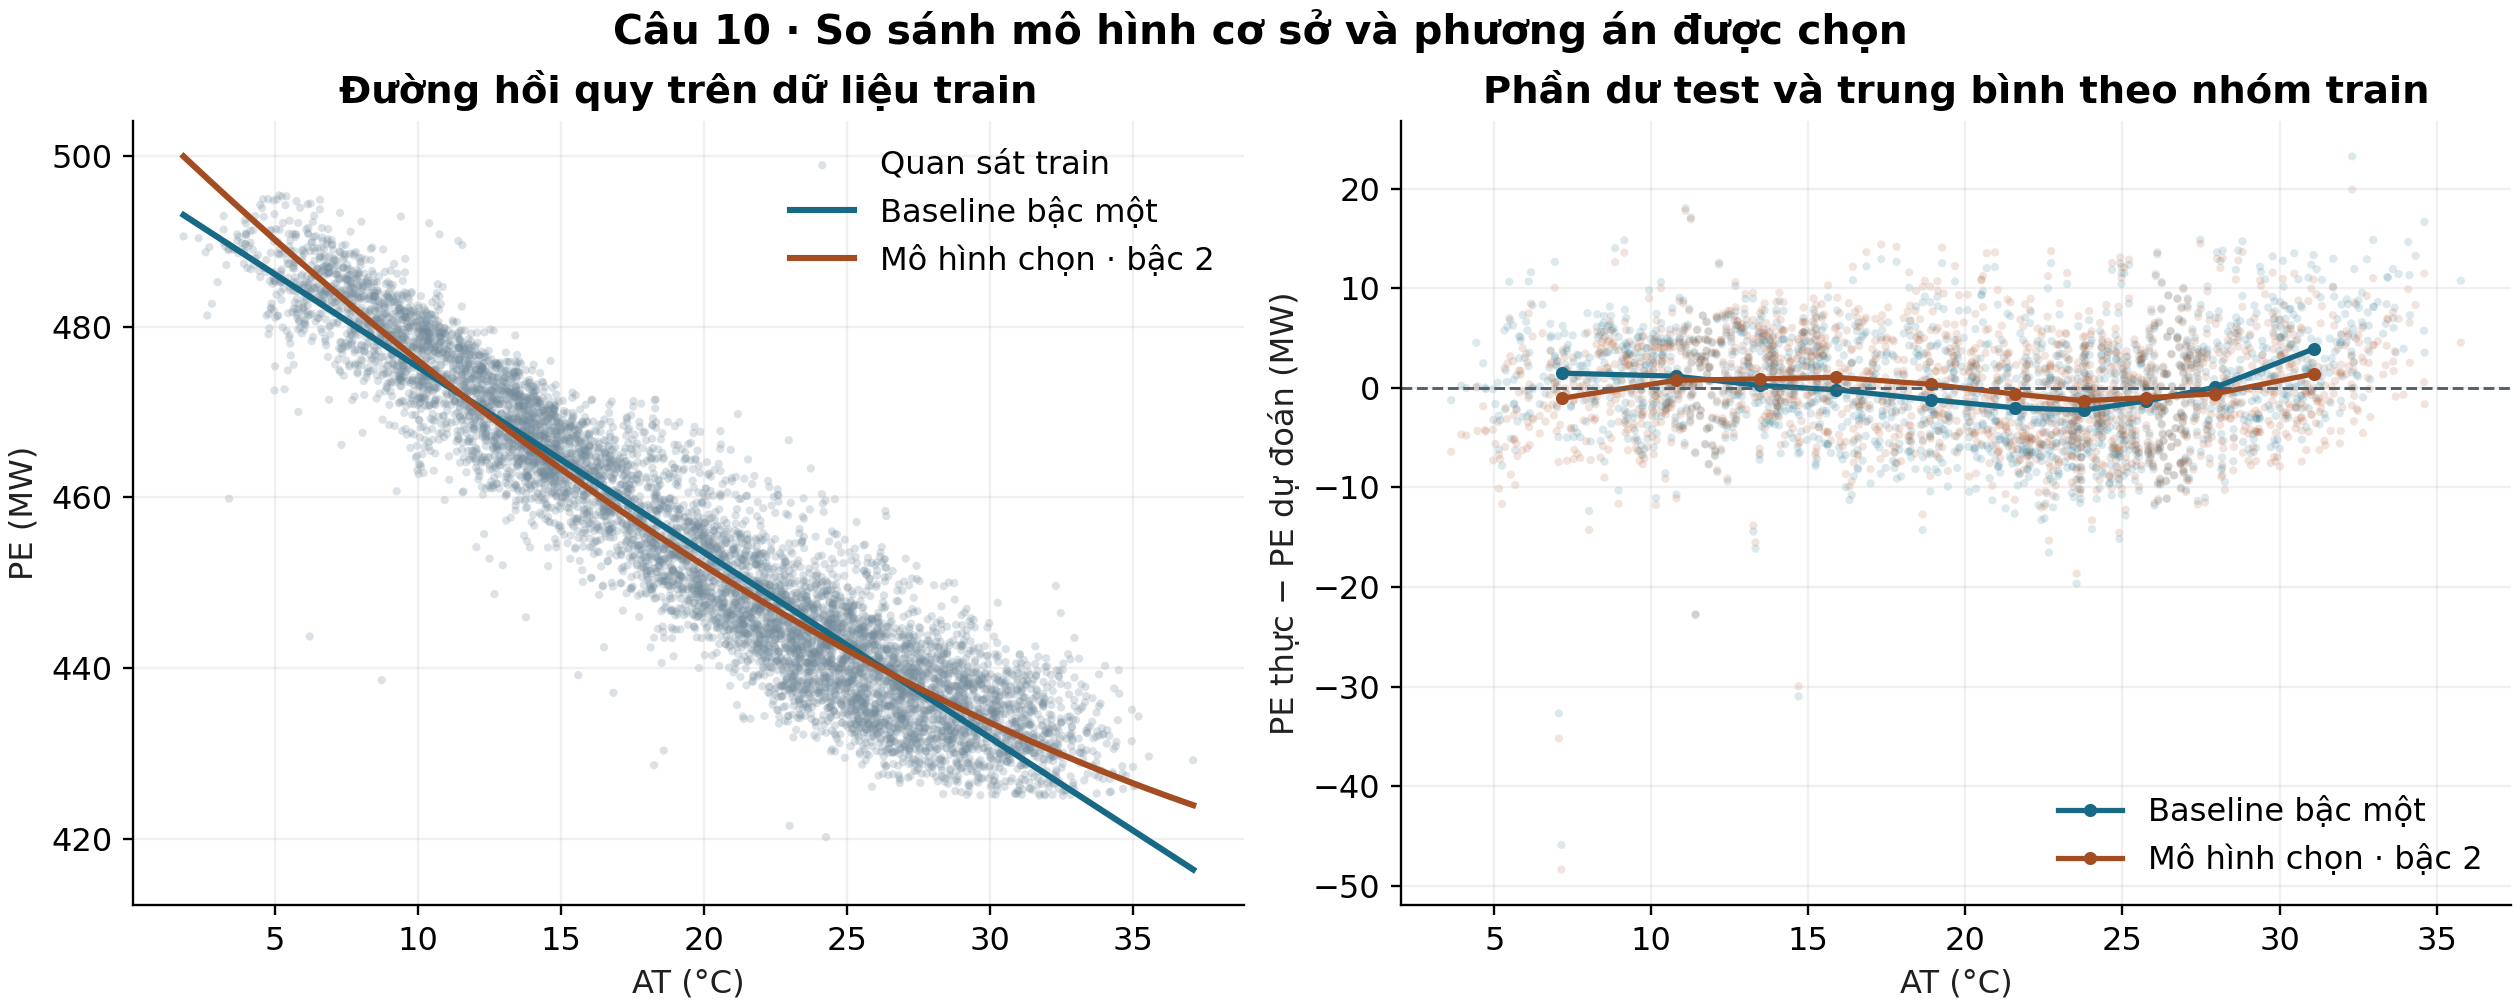

In [45]:
"""Choose a polynomial degree inside train, then compare on the locked test."""
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


_nb_improvement_SEED = 42
_nb_improvement_VALIDATION_FRACTION = 0.2


def _nb_improvement_fit_design(at, degree):
    scaling = {'mean_AT': float(at.mean()), 'std_AT': float(at.std(ddof=0))}
    if degree == 2:
        z_squared = _nb_data_io_design_matrix(at, scaling)[:, 1] ** 2
        scaling.update(mean_z_squared=float(z_squared.mean()),
                       std_z_squared=float(z_squared.std(ddof=0)))
    return scaling


def _nb_improvement_polynomial_design(at, scaling):
    X = _nb_data_io_design_matrix(at, scaling)
    if 'mean_z_squared' in scaling:
        squared = (X[:, 1] ** 2 - scaling['mean_z_squared']) / scaling['std_z_squared']
        X = np.column_stack((X, squared))
    return X


def _nb_improvement_fit_candidate(at, y, degree, config):
    scaling = _nb_improvement_fit_design(at, degree)
    X = _nb_improvement_polynomial_design(at, scaling)
    run = _nb_gradient_descent_gradient_descent(
        X, y, np.zeros(X.shape[1]), learning_rate=config['learning_rate'],
        max_iter=config['max_iter'], tolerance=config['tolerance'],
    )
    if not run['converged'] or run['gradient_norm'] > config['tolerance']:
        raise ValueError(f'Degree {degree} failed the GD stopping criterion.')
    return run, scaling


def _nb_improvement_plot_comparison(train_at, train_y, test_at, predictions, output):
    fig, (fit_ax, resid_ax) = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
    fit_ax.scatter(train_at, train_y, s=8, color='#748b9b', alpha=0.25,
                   edgecolors='none', label='Quan sát train')
    # Use train-defined temperature groups for the diagnostic curves.
    cuts = np.quantile(train_at, np.arange(1, 10) / 10)
    edges = np.r_[-np.inf, cuts, np.inf]
    for label, color, curve, train_resid, test_resid in predictions:
        fit_ax.plot(*curve, linewidth=2.1, color=color, label=label)
        resid_ax.scatter(test_at, test_resid, s=8, color=color, alpha=0.15,
                         edgecolors='none')
        groups = pd.DataFrame({'AT': train_at, 'e': train_resid})
        bins = groups.groupby(pd.cut(train_at, edges), observed=True).mean()
        resid_ax.plot(bins.AT, bins.e, color=color, marker='o', markersize=3.5,
                      linewidth=1.8, label=label)
    resid_ax.axhline(0, color='#52616b', linewidth=1, linestyle='--')
    fit_ax.set(title='Đường hồi quy trên dữ liệu train', ylabel='PE (MW)')
    resid_ax.set(title='Phần dư test và trung bình theo nhóm train', ylabel='PE thực − PE dự đoán (MW)')
    for ax in (fit_ax, resid_ax):
        ax.set_xlabel('AT (°C)')
        ax.grid(alpha=0.18)
        ax.legend(frameon=False)
    fig.suptitle('Câu 10 · So sánh mô hình cơ sở và phương án được chọn',
                 fontsize=14, fontweight='bold')
    fig.savefig(output, dpi=210)
    plt.close(fig)


def _nb_improvement_main():
    X_train, y_train, train, locked_scaling = _nb_data_io_load_training_data()
    results = ROOT / 'results'
    config = json.loads((results / 'baseline_config.json').read_text(encoding='utf-8'))
    contract = json.loads((results / 'data_contract.json').read_text(encoding='utf-8'))
    expected_inputs = {
        'train_sha256': 'data/processed/train.csv',
        'test_sha256': 'data/processed/test.csv',
        'scaling_sha256': 'results/scaling.json',
    }
    if (config['is_mock_data'] or not config['converged']
            or config['data_version'] != contract['data_version']
            or any(config[key] != contract['sha256'][name]
                   for key, name in expected_inputs.items())):
        raise ValueError('Q4 baseline does not match the verified data.')

    at = train.AT.to_numpy(dtype=float)
    order = np.random.default_rng(_nb_improvement_SEED).permutation(len(train))
    n_validation = round(_nb_improvement_VALIDATION_FRACTION * len(train))
    validation, fitting = order[:n_validation], order[n_validation:]
    selection = []
    for degree in (1, 2):
        run, scaling = _nb_improvement_fit_candidate(at[fitting], y_train[fitting], degree, config)
        predicted = _nb_linear_model_predict(_nb_improvement_polynomial_design(at[validation], scaling), run['theta_final'])
        score = _nb_reference_metrics(y_train[validation], predicted)
        selection.append({'degree': degree, 'n_fit': len(fitting), 'n_validation': len(validation),
                          'n_iter': run['n_iter'], **score})
    # Selection uses validation only, with the simpler model winning exact ties.
    selected = min(selection, key=lambda row: (row['MSE'], row['degree']))['degree']
    run, scaling = _nb_improvement_fit_candidate(at, y_train, selected, config)
    theta = run['theta_final']
    expanded_train = _nb_linear_model_predict(_nb_improvement_polynomial_design(at, scaling), theta)

    test = pd.read_csv(ROOT / 'data/processed/test.csv')
    if (len(test) != contract['n_test'] or not test.source_row.is_unique
            or not set(test.source_row).isdisjoint(train.source_row)):
        raise ValueError('Unexpected or overlapping test rows.')
    test_at = test.AT.to_numpy(dtype=float)
    y_test = test.PE.to_numpy(dtype=float)
    X_test = _nb_data_io_design_matrix(test_at, locked_scaling)
    expanded_test = _nb_linear_model_predict(_nb_improvement_polynomial_design(test_at, scaling), theta)

    with np.load(results / 'baseline_run.npz', allow_pickle=False) as baseline:
        gd = baseline['theta_final']
        np.testing.assert_array_equal(gd, baseline['theta_history'][-1])
        np.testing.assert_array_equal(train.source_row, baseline['source_row_train'])
        np.testing.assert_array_equal(test.source_row, baseline['source_row_test'])
        baseline_train, baseline_test = _nb_linear_model_predict(X_train, gd), _nb_linear_model_predict(X_test, gd)
        np.testing.assert_allclose(baseline_train, baseline['pred_train'], atol=1e-9, rtol=0)
        np.testing.assert_allclose(baseline_test, baseline['pred_test'], atol=1e-9, rtol=0)

    rows = []
    for method, degree, train_pred, test_pred in (
        ('baseline_gd', 1, baseline_train, baseline_test),
        ('validation_selected_gd', selected, expanded_train, expanded_test),
    ):
        for split, actual, predicted in (
            ('train', y_train, train_pred), ('test', y_test, test_pred),
        ):
            rows.append({'method': method, 'degree': degree, 'split': split,
                         'n': len(actual), **_nb_reference_metrics(actual, predicted),
                         'mean_residual_MW': float(np.mean(actual - predicted))})
    q8 = pd.read_csv(results / 'q8_metrics.csv').set_index('split')
    for row in rows[:2]:
        np.testing.assert_allclose(
            [row['MSE'], row['RMSE'], row['R2']],
            q8.loc[row['split'], ['MSE_MW2', 'RMSE_MW', 'R2']].to_numpy(float),
            atol=1e-10, rtol=0,
        )

    pd.DataFrame(selection).assign(selected=lambda df: df.degree == selected).to_csv(
        results / 'q10_validation.csv', index=False
    )
    pd.DataFrame(rows).to_csv(results / 'q10_comparison.csv', index=False)
    pd.DataFrame({
        'source_row': test.source_row, 'AT_degC': test_at, 'PE_actual_MW': y_test,
        'PE_baseline_MW': baseline_test, 'PE_selected_MW': expanded_test,
        'residual_baseline_MW': y_test - baseline_test,
        'residual_selected_MW': y_test - expanded_test,
    }).to_csv(results / 'q10_test_predictions.csv', index=False)
    grid = np.linspace(at.min(), at.max(), 200)
    _nb_improvement_plot_comparison(at, y_train, test_at, [
        ('Baseline bậc một', '#176985',
         (grid, _nb_linear_model_predict(_nb_data_io_design_matrix(grid, locked_scaling), gd)),
         y_train - baseline_train, y_test - baseline_test),
        (f'Mô hình chọn · bậc {selected}', '#a44d22',
         (grid, _nb_linear_model_predict(_nb_improvement_polynomial_design(grid, scaling), theta)),
         y_train - expanded_train, y_test - expanded_test),
    ], ROOT / 'figures/q10_comparison.png')

    summary = {
        'data_version': config['data_version'], 'selection_metric': 'validation MSE',
        'validation_seed': _nb_improvement_SEED, 'validation_fraction': _nb_improvement_VALIDATION_FRACTION,
        'selected_degree': selected, 'full_train_scaling': scaling, 'theta': theta.tolist(),
        'full_train_iterations': run['n_iter'], 'full_train_gradient_norm': run['gradient_norm'],
        'test_MSE_reduction_percent': 100 * (1 - rows[3]['MSE'] / rows[1]['MSE']),
        'verification': 'PASS',
    }
    (results / 'q10_summary.json').write_text(json.dumps(summary, indent=2) + '\n',
                                             encoding='utf-8')

_nb_improvement_main()

_q10_validation = pd.read_csv(ROOT / "results/q10_validation.csv")
_q10_comparison = pd.read_csv(ROOT / "results/q10_comparison.csv")
_q10_summary = json.loads((ROOT / "results/q10_summary.json").read_text(encoding="utf-8"))
display(Markdown("### Kết quả câu 10 — Chọn bậc mô hình bằng validation"))
display(Markdown("**So sánh các bậc đa thức trên validation (chỉ dùng train)**")); display(_q10_validation.round(6))
display(Markdown("**So sánh baseline và mô hình cải thiện trên train/test**")); display(_q10_comparison.round(6))
_q10_mu = _q10_summary["full_train_scaling"]["mean_AT"]
_q10_sd = _q10_summary["full_train_scaling"]["std_AT"]
_q10_theta = _q10_summary["theta"]
_q10_test = _q10_comparison[_q10_comparison["split"] == "test"].set_index("method")
_q10_reduction = _q10_summary["test_MSE_reduction_percent"]
print(f"Bậc được chọn: {_q10_summary['selected_degree']}; z = (AT - {_q10_mu:.6f}) / {_q10_sd:.6f}.")
print(f"Mô hình đa thức: PE_hat = {_q10_theta[0]:.6f} {_q10_theta[1]:+.6f}·z {_q10_theta[2]:+.6f}·z².")
print(f"Test MSE giảm từ {_q10_test.loc['baseline_gd', 'MSE']:.6f} xuống {_q10_test.loc['validation_selected_gd', 'MSE']:.6f} MW² ({_q10_reduction:.2f}%).")
display(Markdown("**So sánh hiệu năng mô hình**")); display(Image(filename=str(ROOT / "figures/q10_comparison.png")))
